# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 24                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = True      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

# Предметные атрибуты событий (XLSX) и названия классов цен (JSON) для каждого варианта.
# detail — описательный столбец события: «pair» — пара «откуда — куда», «one» — одно значение;
# kind — второй описательный столбец (4 значения); classes — классы цен от дешёвого к дорогому.
# Эти столбцы описывают событие, но в расчёт выручки не входят: выручка = объём × цена.
EVENT_ATTRS = {
    1: {"detail": ["route", "pair", None], "kind": ["aircraft_type", ["Узкофюзеляжный", "Широкофюзеляжный", "Региональный", "Турбовинтовой"]], "classes": ["Эконом", "Комфорт", "Бизнес"]},
    2: {"detail": ["payment_method", "one", ["Наличные", "Банковская карта", "СБП", "Карта + бонусы"]], "kind": ["checkout_type", ["Касса", "Касса самообслуживания", "Онлайн-заказ", "Экспресс-касса"]], "classes": ["Бакалея", "Бытовая химия", "Электроника"]},
    3: {"detail": ["route", "pair", None], "kind": ["vehicle_type", ["Фура 20 т", "Рефрижератор", "Малотоннажный", "Контейнеровоз"]], "classes": ["Базовый", "Срочный", "Экспресс"]},
    4: {"detail": ["network", "one", ["2G", "3G", "4G", "5G"]], "kind": ["session_type", ["Голос", "Мобильный интернет", "Роуминг", "SMS-пакет"]], "classes": ["Базовый", "Безлимитный", "Корпоративный"]},
    5: {"detail": ["service_channel", "one", ["Касса", "Банкомат", "Интернет-банк", "Мобильное приложение"]], "kind": ["client_segment", ["Массовый", "Зарплатный", "Премиальный", "МСБ"]], "classes": ["Переводы", "Валютные операции", "Инкассация"]},
    6: {"detail": ["booking_channel", "one", ["Сайт отеля", "Онлайн-агрегатор", "Турагентство", "Корпоративный договор"]], "kind": ["guest_type", ["Деловой", "Туристический", "Семейный", "Групповой"]], "classes": ["Стандарт", "Делюкс", "Люкс"]},
    7: {"detail": ["course_area", "one", ["IT", "Иностранные языки", "Управление", "Подготовка к экзаменам"]], "kind": ["audience", ["Школьники", "Студенты", "Взрослые", "Корпоративные клиенты"]], "classes": ["Онлайн", "Смешанный", "Очный"]},
    8: {"detail": ["specialty", "one", ["Терапия", "Педиатрия", "Стоматология", "Кардиология", "Неврология", "Офтальмология"]], "kind": ["payment_type", ["ОМС", "ДМС", "Платно", "Абонемент"]], "classes": ["Консультация", "Диагностика", "Процедура"]},
    9: {"detail": ["voltage_level", "one", ["ВН", "СН-1", "СН-2", "НН"]], "kind": ["contract_type", ["Энергоснабжение", "Купля-продажа", "Регулируемый", "Свободный рынок"]], "classes": ["Население", "Бюджетные организации", "Промышленность"]},
    10: {"detail": ["fulfillment", "one", ["Склад площадки", "Склад продавца", "Экспресс-доставка", "Самовывоз"]], "kind": ["order_channel", ["Мобильное приложение", "Сайт", "Партнёрский сайт", "Реклама в соцсетях"]], "classes": ["Товары для дома", "Одежда", "Электроника"]},
    11: {"detail": ["line", "one", ["Маршрут 1", "Маршрут 5", "Маршрут 12", "Маршрут 18", "Маршрут 24", "Маршрут 31", "Маршрут 37", "Маршрут 42", "Маршрут 55", "Маршрут 63", "Маршрут 70", "Маршрут 88"]], "kind": ["vehicle_type", ["Автобус", "Трамвай", "Троллейбус", "Электробус"]], "classes": ["Разовый", "Проездной на месяц", "Проездной на год"]},
    12: {"detail": ["client_type", "one", ["Физическое лицо", "ИП", "Малый бизнес", "Крупный бизнес"]], "kind": ["sales_channel", ["Офис агентства", "Онлайн", "Банк-партнёр", "Автосалон"]], "classes": ["ОСАГО", "Имущество", "КАСКО"]},
    13: {"detail": ["route", "pair", None], "kind": ["wagon_type", ["Полувагон", "Крытый вагон", "Цистерна", "Платформа"]], "classes": ["Уголь", "Зерно", "Нефтепродукты"]},
    14: {"detail": ["service_format", "one", ["В зале", "Навынос", "Доставка", "Банкет"]], "kind": ["daypart", ["Завтрак", "Обед", "Ужин", "Поздний вечер"]], "classes": ["Напитки", "Основные блюда", "Фирменные сеты"]},
    15: {"detail": ["visit_zone", "one", ["Тренажёрный зал", "Бассейн", "Групповые программы", "Единоборства"]], "kind": ["client_type", ["Новый клиент", "Постоянный", "Корпоративный", "Гостевой визит"]], "classes": ["Разовый", "Месячный", "Годовой"]},
    16: {"detail": ["site_type", "one", ["Жилое строительство", "Дорожные работы", "Промышленный объект", "Коммунальные работы"]], "kind": ["rental_mode", ["С оператором", "Без оператора", "Долгосрочная", "Почасовая"]], "classes": ["Мини-погрузчик", "Экскаватор", "Автокран"]},
    17: {"detail": ["route", "pair", None], "kind": ["parcel_size", ["Документы", "Малая (S)", "Средняя (M)", "Крупная (L)"]], "classes": ["Стандарт", "Ускоренная", "Экспресс"]},
    18: {"detail": ["client_channel", "one", ["Розничные сети", "HoReCa", "Независимая розница", "Онлайн-ретейл"]], "kind": ["delivery_mode", ["Доставка дистрибьютора", "Самовывоз", "Транзит со склада", "Кросс-докинг"]], "classes": ["Бакалея", "Напитки", "Кондитерские изделия"]},
    19: {"detail": ["car_class", "one", ["Отечественный", "Иномарка эконом", "Иномарка бизнес", "Коммерческий транспорт"]], "kind": ["visit_reason", ["Плановое ТО", "Ремонт", "Шиномонтаж", "Диагностика"]], "classes": ["Слесарные работы", "Электрика и диагностика", "Кузовные работы"]},
    20: {"detail": ["platform", "one", ["iOS", "Android", "Веб", "Smart TV"]], "kind": ["acquisition", ["Органика", "Реклама", "Промокод", "Партнёр"]], "classes": ["Базовый", "Стандарт", "Премиум"]},
    21: {"detail": ["buyer_type", "one", ["Элеватор", "Перерабатывающий завод", "Экспорт", "Трейдер"]], "kind": ["transport", ["Автотранспорт", "Железная дорога", "Речной транспорт", "Самовывоз"]], "classes": ["Пшеница", "Подсолнечник", "Соя"]},
    22: {"detail": ["sales_channel", "one", ["Торговый зал", "Интернет-магазин", "Отдел для профи", "Самовывоз со склада"]], "kind": ["client_type", ["Частный клиент", "Бригада", "Строительная компания", "Дизайнер"]], "classes": ["Крепёж и расходники", "Отделочные материалы", "Инструмент"]},
    23: {"detail": ["route", "pair", ["Новороссийск", "Санкт-Петербург", "Владивосток", "Восточный", "Усть-Луга", "Мурманск", "Калининград", "Шанхай", "Нинбо", "Пусан", "Мумбаи", "Стамбул"]], "kind": ["cargo_mode", ["Импорт", "Экспорт", "Транзит", "Каботаж"]], "classes": ["20' стандартный", "40' стандартный", "40' рефрижератор"]},
    24: {"detail": ["sales_channel", "one", ["Торговый зал", "Онлайн-бронирование", "Доставка", "Корпоративный заказ"]], "kind": ["shift", ["Утренняя смена", "Дневная смена", "Вечерняя смена", "Ночная смена"]], "classes": ["Безрецептурные (OTC)", "Рецептурные (Rx)", "Специализированная терапия"]},
    25: {"detail": ["hall", "one", ["Зал 1", "Зал 2", "Зал 3", "Зал 4", "Зал 5", "VIP-зал"]], "kind": ["genre", ["Анимация", "Драма", "Комедия", "Фантастика"]], "classes": ["2D", "3D", "IMAX"]},
    26: {"detail": ["customer_type", "one", ["Дилер", "Прямой клиент", "Экспорт", "Госзаказ"]], "kind": ["shipping", ["Железная дорога", "Автотранспорт", "Самовывоз", "Контейнер"]], "classes": ["Марка М1", "Марка М2", "Марка М3 (премиум)"]},
    27: {"detail": ["audience_age", "one", ["18–24", "25–34", "35–44", "45+"]], "kind": ["device", ["Смартфон", "Компьютер", "Smart TV", "Планшет"]], "classes": ["Баннер", "Нативный", "Видео"]},
    28: {"detail": ["building_type", "one", ["Панельный дом", "Кирпичный дом", "Монолит", "Новостройка"]], "kind": ["payment_channel", ["Банк", "Госуслуги", "Приложение УК", "Касса УК"]], "classes": ["Содержание жилья", "Водоснабжение", "Отопление"]},
    29: {"detail": ["trip_zone", "one", ["Центр", "Спальный район", "Аэропорт", "Межгород"]], "kind": ["client_type", ["Новый", "Постоянный", "Корпоративный", "Студенческий"]], "classes": ["Эконом", "Комфорт", "Премиум"]},
    30: {"detail": ["route", "pair", None], "kind": ["aircraft_type", ["Узкофюзеляжный", "Широкофюзеляжный", "Региональный", "Турбовинтовой"]], "classes": ["Эконом", "Комфорт", "Бизнес"]},
}

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    cfg = dict(found[0])
    cfg["event_attrs"] = EVENT_ATTRS[v]
    return cfg

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"       описательные столбцы: {CFG['event_attrs']['detail'][0]}, {CFG['event_attrs']['kind'][0]}")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"       классы цен: {', '.join(CFG['event_attrs']['classes'])}")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 24 — Аптечные сети
Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»

CSV  : Аптеки        (справочник субъектов)
XLSX : Продажи          (события, объём в единицах: упаковок)
       описательные столбцы: sales_channel, shift
JSON : Цены препаратов          (цены, разрез: группа препаратов)
       классы цен: Безрецептурные (OTC), Рецептурные (Rx), Специализированная терапия

Объём генерации: субъектов 12, событий 3 000, уровень дефектов ★
Аналитическая задача: Вклад товарных групп и сравнение точек


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

**Описательные столбцы событий.** Кроме ключей, даты и объёма, в `events.xlsx` есть два столбца, которые описывают событие на языке вашей предметной области: для перевозок — маршрут, для аптек — канал продаж и смена, для кинотеатров — зал и жанр и т. д. Классы цен в `prices.json` тоже названы по предметной области. Описательные столбцы участвуют в аудите (профиль, полнота, допустимые значения) и могут использоваться в дополнительной аналитике, но в расчёт выручки не входят: выручка = объём × цена. Список столбцов вашего варианта печатает шаг 1.1.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    # описательные столбцы события зависят от предметной области (см. EVENT_ATTRS в шаге 1.1);
    # порядок обращений к генератору случайных чисел общий для всех вариантов
    ea = cfg["event_attrs"]
    first, second = rng.choice(regions, m), rng.choice(regions, m)
    d_col, d_kind, d_vals = ea["detail"]
    if d_kind == "pair":                                   # «откуда — куда»: города или порты
        names = dict(zip(regions, d_vals or regions))
        detail = [f"{names[a]} — {names[b]}" for a, b in zip(first, second)]
    else:                                                  # одно значение: канал, смена, зал и т. п.
        detail = [d_vals[regions.index(b) % len(d_vals)] for b in second]
    k_col, k_vals = ea["kind"]
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        d_col: detail,
        "volume_units": volume,
        k_col: rng.choice(k_vals, m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = list(cfg["event_attrs"]["classes"])         # от дешёвого к дорогому
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       13   размер:      0.8 КБ
events.xlsx     строк:    3 000   размер:    104.5 КБ
prices.json     строк:    6 064   размер:    845.8 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [48]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []

    for col in df.columns:
        s = df[col]
        non_null = s.notna() & (s.astype(str).str.strip() != "")
        sample = s[non_null].astype(str).head(2).tolist()
        rows.append({
            "источник": name,
            "колонка": col,
            "тип": str(s.dtype),
            "заполнено, %": round(float(non_null.mean()) * 100, 1),
            "уникальных": int(s.nunique(dropna=True)),
            "примеры": " | ".join(sample)[:42]
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
print("ПРОФИЛЬ ИСТОЧНИКОВ")
display(profiles)


# ------------------------------------------------------------------ TODO 3.2
# Заполните журнал проблем качества по шести измерениям. Для каждой найденной проблемы —
# строка с полями: измерение, источник, проблема, число строк, решение.
#   Полнота        — пропуски по колонкам
#   Уникальность   — полные дубликаты и повторы ключей (entity_id, event_id, price_id)
#   Согласованность— два формата даты, числа строками с валютой и пробелами
#   Валидность     — отрицательные цены, нулевой объём
#   Целостность    — записи с внешним ключом, которого нет в справочнике (в обе стороны)
#   Точность       — выбросы цен по правилу 3×IQR
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

SRC_E, SRC_EV, SRC_P = list(SOURCES)
DATE_ISO = r"^\d{4}-\d{2}-\d{2}$"
DATE_RU = r"^\d{2}\.\d{2}\.\d{4}$"

def is_blank(s):
    return s.isna() | (s.astype(str).str.strip() == "")

def raw_number(s):
    """Грубое числовое значение для аудита: только «чистые» числа, остальное → NaN."""
    return pd.to_numeric(s, errors="coerce")


for name, df in SOURCES.items():
    for col in df.columns:
        n_blank = int(is_blank(df[col]).sum())
        if n_blank:
            add_issue("Полнота", name, f"пропуски в колонке {col}", n_blank,
                      "оставить пропуском (не 0); строки без цены — в карантин")


for name, df, key in [(SRC_E, raw_entities, "entity_id"), (SRC_EV, raw_events, "event_id"),
                      (SRC_P, raw_prices, "price_id")]:
    n_full = int(df.astype(str).duplicated().sum())
    n_key = int(df[key].duplicated().sum())
    add_issue("Уникальность", name, "полные дубликаты строк", n_full,
              "удалить, оставив первую запись" if n_full else "дефект не обнаружен")
    add_issue("Уникальность", name, f"повторы ключа {key}", n_key,
              "дедупликация по ключу, первая запись" if n_key else "дефект не обнаружен")


dates = raw_events["event_date"].astype(str).str.strip()
add_issue("Согласованность", SRC_EV, "дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД",
          dates.str.match(DATE_RU).sum(), "разобрать оба формата, хранить ГГГГ-ММ-ДД")
add_issue("Согласованность", SRC_EV, "дата не распознана ни в одном формате",
          (~dates.str.match(DATE_ISO) & ~dates.str.match(DATE_RU) & raw_events["event_date"].notna()).sum(),
          "в карантин")
vol = raw_events["volume_units"]
add_issue("Согласованность", SRC_EV, "объём записан текстом с пробелами",
          (vol.notna() & (vol.astype(str) != vol.astype(str).str.strip())).sum(),
          "убрать пробелы, привести к числу")
price_is_text = raw_prices["unit_price"].map(lambda v: isinstance(v, str))
add_issue("Согласованность", SRC_P, "цена строкой с валютой и пробелом-разделителем",
          price_is_text.sum(), "очистить строку, привести к числу")
names = raw_entities["entity_name"].astype(str)
add_issue("Согласованность", SRC_E, "имя с лишними пробелами или в верхнем регистре",
          ((names != names.str.strip()) | (names == names.str.upper())).sum(),
          "убрать пробелы, привести регистр к виду справочника")


price_num = raw_number(raw_prices["unit_price"])
vol_num = raw_number(raw_events["volume_units"])
add_issue("Валидность", SRC_P, "цена ≤ 0", (price_num <= 0).sum(),
          "в карантин" if (price_num <= 0).any() else "дефект не обнаружен")
add_issue("Валидность", SRC_EV, "объём ≤ 0", (vol_num <= 0).sum(),
          "в карантин" if (vol_num <= 0).any() else "дефект не обнаружен")


known_entities = set(raw_entities["entity_id"])
known_events = set(raw_events["event_id"])
orph_ev = ~raw_events["entity_id"].isin(known_entities)
orph_p = ~raw_prices["event_id"].isin(known_events)
add_issue("Целостность", SRC_EV, "entity_id нет в справочнике", orph_ev.sum(),
          "в карантин quarantine_fk" if orph_ev.any() else "дефект не обнаружен")
add_issue("Целостность", SRC_P, "event_id нет среди событий", orph_p.sum(),
          "в карантин quarantine_fk" if orph_p.any() else "дефект не обнаружен")
add_issue("Целостность", SRC_E, "субъект без единого события",
          (~raw_entities["entity_id"].isin(set(raw_events["entity_id"]))).sum(),
          "оставить: справочник может быть шире фактов")
add_issue("Целостность", SRC_EV, "событие без единой цены",
          (~raw_events["event_id"].isin(set(raw_prices["event_id"]))).sum(),
          "не войдёт в выручку — отметить в выводах")


OUTLIER_K = 3.0
p_aud = raw_prices.assign(price=price_num).dropna(subset=["price"])
p_aud = p_aud[p_aud["price"] > 0]
n_out = 0
for _, g in p_aud.groupby("price_class"):
    q1, q3 = g["price"].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out += int(((g["price"] < q1 - OUTLIER_K * iqr) | (g["price"] > q3 + OUTLIER_K * iqr)).sum())
add_issue("Точность", SRC_P, f"выбросы цены по правилу {OUTLIER_K:g}×IQR внутри класса", n_out,
          "проверить у владельца источника, не удалять" if n_out else "дефект не обнаружен")

issues_df = pd.DataFrame(issues)
found = issues_df[issues_df["строк"] > 0]
print(f"Проверок выполнено: {len(issues_df)} | проблем найдено: {len(found)} "
      f"| измерений с проблемами: {found['измерение'].nunique()} из 6")
display(issues_df.sort_values(["строк"], ascending=False).reset_index(drop=True))

# ------------------------------------------------------------------ TODO 3.3
# Определите кардинальность связей entities → events и events → prices: среднее и максимальное
# число потомков. Ответьте письменно: что произойдёт с суммой выручки при наивном JOIN трёх таблиц?

# Количество цен на каждое событие
prices_per_event = raw_prices.groupby("event_id").size()

# Количество событий у каждого субъекта
events_per_entity = raw_events.groupby("entity_id").size()

# Таблица кардинальности
card = pd.DataFrame({
    "связь": ["entities → events", "events → prices"],
    "тип": ["1 : N", "1 : N"],
    "в среднем потомков": [
        round(len(raw_events) / max(raw_entities["entity_id"].nunique(), 1), 2),
        round(float(prices_per_event.mean()), 2)
    ],
    "максимум": [
        int(events_per_entity.max()),
        int(prices_per_event.max())
    ]
})

print("\nКАРДИНАЛЬНОСТЬ СВЯЗЕЙ")
display(card)

# Вывод
print(
    f"\nНа одно событие приходится в среднем "
    f"{prices_per_event.mean():.2f} строк цен."
)

print(
    "Ответ на вопрос в задании про наивный join:"
    "При наивном join таблиц entities, events, prices строки событий будут размножаться по количеству связанных цен. В результате сумма выручки будет завышена и не соответствовать действительности. То есть аналитику в данном случае проводить некорректно"
)

# ИНТЕГРАЛЬНАЯ ОЦЕНКА КАЧЕСТВА

# 1 подход - классический

dq_score = round(
    100 * (
        1 - quality["строк"].sum() /
        max(sum(len(d) for d in SOURCES.values()), 1)
    ), 1
)

print(
    f"\nИнтегральная оценка качества: {dq_score} % "
    "(примерная доля строк без зафиксированных проблем)"
)

print(f'\nОднако у данного подхода расчета интегральной оценки качества есть нюанс - проблемные строки могут иметь несколько проблем и попадать в данную выборку дважды (Например, если одновременно пропущены значения и некоректны форматы). Для этого продемонстрируем методику расчета интегральной оценки качества для уникальных дефектных строк')
# ИНТЕГРАЛЬНАЯ ОЦЕНКА КАЧЕСТВА ДАННЫХ
# Учитываем каждую дефектную строку только один раз.

bad_entities = set()
bad_events = set()
bad_prices = set()

# 1. CSV — справочник аптек

bad_entities.update(
    raw_entities.index[
        raw_entities.duplicated(keep=False)
    ]
)

# Пропуски
for col in raw_entities.columns:
    mask = (
        raw_entities[col].isna()
        | raw_entities[col].astype(str).str.strip().eq("")
    )
    bad_entities.update(raw_entities.index[mask])

# 2. XLSX — события продаж

for col in raw_events.columns:
    mask = (
        raw_events[col].isna()
        | raw_events[col].astype(str).str.strip().eq("")
    )
    bad_events.update(raw_events.index[mask])

# Второй формат даты
date_mask = raw_events["event_date"].astype(str).str.match(
    r"\d{2}\.\d{2}\.\d{4}"
)

bad_events.update(raw_events.index[date_mask])

# Некорректный или неположительный объём
volumes = numeric_like(raw_events["volume_units"])

bad_events.update(
    raw_events.index[
        volumes.isna() | (volumes <= 0)
    ]
)

# Дубликаты ключей
bad_events.update(
    raw_events.index[
        raw_events["event_id"].duplicated(keep=False)
    ]
)

# Нарушение ссылочной целостности
bad_events.update(
    raw_events.index[
        ~raw_events["entity_id"].isin(
            raw_entities["entity_id"]
        )
    ]
)

# 3. JSON — цены

for col in raw_prices.columns:
    mask = (
        raw_prices[col].isna()
        | raw_prices[col].astype(str).str.strip().eq("")
    )
    bad_prices.update(raw_prices.index[mask])

# Некорректные и отрицательные цены
prices_num = numeric_like(raw_prices["unit_price"])

bad_prices.update(
    raw_prices.index[
        prices_num.isna() | (prices_num <= 0)
    ]
)

# Дубликаты ключей
bad_prices.update(
    raw_prices.index[
        raw_prices["price_id"].duplicated(keep=False)
    ]
)

# Цены без соответствующего события
bad_prices.update(
    raw_prices.index[
        ~raw_prices["event_id"].isin(
            raw_events["event_id"]
        )
    ]
)

# Выбросы по правилу 3*IQR
q1 = prices_num.quantile(0.25)
q3 = prices_num.quantile(0.75)
iqr = q3 - q1

outlier_mask = (
    (prices_num < q1 - 3 * iqr)
    | (prices_num > q3 + 3 * iqr)
)

bad_prices.update(
    raw_prices.index[outlier_mask.fillna(False)]
)

# 4. Расчёт уникальных дефектных строк
total_rows = sum(
    len(df) for df in SOURCES.values()
)

defect_rows = (
    len(bad_entities)
    + len(bad_events)
    + len(bad_prices)
)

clean_rows = total_rows - defect_rows

dq_score_unique = round(
    clean_rows / total_rows * 100, 2
)

print("ИНТЕГРАЛЬНАЯ ОЦЕНКА КАЧЕСТВА")
print(f"Всего исходных строк: {total_rows}")
print(f"Строк с дефектами: {defect_rows}")
print(f"Строк без обнаруженных дефектов: {clean_rows}")
print(f"Интегральная оценка качества по уникальным записям: {dq_score_unique}%")

if dq_score != dq_score_unique:
  print ('\nИнтегральная оценка качества с учетом и без учета уникальных записей отличаются, значит, существует как минимум одна запись, имеющая более одного дефекта')

print('В данном случае, оба показателя свидетельствуют о высоком качестве исходных данных, т.к. интегральная оценка качества данных более 99%')


ПРОФИЛЬ ИСТОЧНИКОВ


,источник,колонка,тип,"заполнено, %",уникальных,примеры
0,CSV · Аптеки,entity_id,object,100.00,12,E001 | E002
1,CSV · Аптеки,entity_name,object,100.00,12,Аптеки «Уфа» | Аптеки «Ростов-на-Дону»
2,CSV · Аптеки,region,object,100.00,12,Уфа | Ростов-на-Дону
3,CSV · Аптеки,founded_year,object,100.00,11,2004 | 2017
4,XLSX · Продажи,event_id,object,100.00,3000,EV000001 | EV000002
5,XLSX · Продажи,entity_id,object,100.00,12,E003 | E003
6,XLSX · Продажи,event_date,object,100.00,375,2025-11-06 | 2025-04-11
7,XLSX · Продажи,sales_channel,object,100.00,4,Доставка | Онлайн-бронирование
8,XLSX · Продажи,volume_units,object,99.70,371,201 | 207
9,XLSX · Продажи,shift,object,100.00,4,Ночная смена | Вечерняя смена


Проверок выполнено: 20 | проблем найдено: 8 | измерений с проблемами: 3 из 6


,измерение,источник,проблема,строк,решение
0,Полнота,JSON · Цены препаратов,пропуски в колонке unit_price,13,оставить пропуском (не 0); строки без цены — в...
1,Согласованность,JSON · Цены препаратов,цена строкой с валютой и пробелом-разделителем,13,"очистить строку, привести к числу"
2,Согласованность,XLSX · Продажи,дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД,10,"разобрать оба формата, хранить ГГГГ-ММ-ДД"
3,Полнота,XLSX · Продажи,пропуски в колонке volume_units,10,оставить пропуском (не 0); строки без цены — в...
4,Согласованность,XLSX · Продажи,объём записан текстом с пробелами,10,"убрать пробелы, привести к числу"
5,Уникальность,CSV · Аптеки,полные дубликаты строк,1,"удалить, оставив первую запись"
6,Уникальность,CSV · Аптеки,повторы ключа entity_id,1,"дедупликация по ключу, первая запись"
7,Согласованность,CSV · Аптеки,имя с лишними пробелами или в верхнем регистре,1,"убрать пробелы, привести регистр к виду справо..."
8,Уникальность,JSON · Цены препаратов,повторы ключа price_id,0,дефект не обнаружен
9,Уникальность,JSON · Цены препаратов,полные дубликаты строк,0,дефект не обнаружен



КАРДИНАЛЬНОСТЬ СВЯЗЕЙ


,связь,тип,в среднем потомков,максимум
0,entities → events,1 : N,250.00,393
1,events → prices,1 : N,2.02,3



На одно событие приходится в среднем 2.02 строк цен.
Ответ на вопрос в задании про наивный join:При наивном join таблиц entities, events, prices строки событий будут размножаться по количеству связанных цен. В результате сумма выручки будет завышена и не соответствовать действительности. То есть аналитику в данном случае проводить некорректно

Интегральная оценка качества: 99.5 % (примерная доля строк без зафиксированных проблем)

Однако у данного подхода расчета интегральной оценки качества есть нюанс - проблемные строки могут иметь несколько проблем и попадать в данную выборку дважды (Например, если одновременно пропущены значения и некоректны форматы). Для этого продемонстрируем методику расчета интегральной оценки качества для уникальных дефектных строк
ИНТЕГРАЛЬНАЯ ОЦЕНКА КАЧЕСТВА
Всего исходных строк: 9077
Строк с дефектами: 35
Строк без обнаруженных дефектов: 9042
Интегральная оценка качества по уникальным записям: 99.61%

Интегральная оценка качества с учетом и без учета уника

**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [49]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})


# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    Подсказка: убрать всё, кроме цифр, запятой, точки и минуса; решить, чем является запятая —
    десятичным разделителем или разделителем разрядов; затем pd.to_numeric(errors="coerce")."""
    cleaned = (
        series.astype(str)
        .str.replace("\u00a0", " ", regex=False)
        .str.replace(r"[^\d,.\-]", "", regex=True)
        .str.replace(" ", "", regex=False)
    )

    # Если присутствуют и запятая, и точка, то считаем запятую разделителем тысяч.
    mask = cleaned.str.contains(",", regex=False) & \
           cleaned.str.contains(".", regex=False)

    cleaned.loc[mask] = cleaned.loc[mask].str.replace(
        ",", "", regex=False
    )

    # Если есть только запятая — считаем её десятичным разделителем.
    cleaned.loc[~mask] = cleaned.loc[~mask].str.replace(
        ",", ".", regex=False
    )

    return pd.to_numeric(cleaned, errors="coerce")

print('Примечание. Использование запятой в качестве разделителя разрядов (например, тысяч) не является общепринятым в международных системах. Однако т.к. проект учебный и задание подразумевает необходимость определить "чем является запятая — десятичным разделителем или разделителем разрядов", то в задании используется именно такой подход')

# Преобразование дат
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    iso = pd.to_datetime(
        series, format="%Y-%m-%d", errors="coerce"
    )

    ru = pd.to_datetime(
        series, format="%d.%m.%Y", errors="coerce"
    )

    return iso.fillna(ru)

# Проверка преобразований (взяла примеры из комментария варианта и добавила ещё парочку, чтобы проверить, что функции точно отрабатывают хорошо)
_t = to_number(pd.Series([
    "8 500,00 ₽",
    "180 ",
    None,
    "1,234.56",
    4200.5,
    "8 500.00 ₽"
]))

assert _t.iloc[0] == 8500.0
assert _t.iloc[1] == 180.0
assert pd.isna(_t.iloc[2])
assert _t.iloc[3] == 1234.56
assert _t.iloc[4] == 4200.5
assert _t.iloc[5] == 8500.0

# Проверка преобразования дат
_d = to_date(pd.Series([
    "2025-03-17",
    "17.03.2025",
    "ляляля",
    None
]))

assert _d.iloc[0] == _d.iloc[1] == pd.Timestamp("2025-03-17")
assert _d.iloc[2:].isna().all()

print("Функции to_number и to_date прошли проверку")

# ------------------------------------------------------------------ TODO 4.3
# Очистите три набора и заполните журнал через log_step(). Правила:
#   * дубликаты удаляются по ключу (entity_id, event_id, price_id), остаётся первая запись;
#   * имена субъектов приводятся к единому виду (лишние пробелы, регистр);
#   * строки с нарушенной ссылочной целостностью и непригодными значениями уходят
#     в переменные quarantine_fk и quarantine_price, а не удаляются молча;
#   * пропуск остаётся пропуском: не заменяйте его нулём.
# На выходе должны быть: entities, events_valid, prices_valid, quarantine_fk, quarantine_price.


# СПРАВОЧНИК АПТЕК

n0 = len(raw_entities)

# Удаляем полные дубликаты
entities = raw_entities.drop_duplicates().copy()

# Нормализуем названия аптек, удаляем лишние пробелы, приводим к единому регистру
entities["entity_name"] = (
    entities["entity_name"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

# Приводим год основания к целочисленному типу
entities["founded_year"] = pd.to_numeric(
    entities["founded_year"], errors="coerce"
).astype("Int64")

# Удаляем повторы ключа entity_id
entities = entities.drop_duplicates(
    subset=["entity_id"], keep="first"
)

log_step(
    "Справочник аптек: дубликаты и нормализация",
    n0,
    len(entities),
    "Удалены полные дубликаты и повторы entity_id, "
    "названия аптек приведены к единому виду"
)


# СОБЫТИЯ ПРОДАЖ

n0 = len(raw_events)

# Удаляем повторяющиеся event_id
events = raw_events.drop_duplicates(
    subset=["event_id"], keep="first"
).copy()

log_step(
    "Продажи: удаление дубликатов",
    n0,
    len(events),
    "Оставлена первая запись для каждого event_id"
)

# Преобразуем даты и объёмы продаж ранее написанными функциями на шаге 4.2
events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])

# Считаем некорректные значения
bad_dates = int(events["event_date"].isna().sum())
bad_volume = int(
    events["volume_units"].isna().sum()
    + (events["volume_units"] <= 0).sum()
)

# Выносим события с неизвестным entity_id в карантин
n0 = len(events)

known_entities = set(entities["entity_id"])

quarantine_fk = events[
    ~events["entity_id"].isin(known_entities)
].copy()

events = events[
    events["entity_id"].isin(known_entities)
].copy()

log_step(
    "Продажи: проверка ссылочной целостности",
    n0,
    len(events),
    f"В карантин вынесено {len(quarantine_fk)} "
    "событий с неизвестным entity_id"
)

# Отдельно выносим данные с карантина для дальнейшего анализа (если бы данные были не синтетическими, а реальными, то необходимо было бы обратиться к источнику для уточнения данных)
quarantine_events = events[
    events["event_date"].isna()
    | events["volume_units"].isna()
    | (events["volume_units"] <= 0)
].copy()

events_valid = events.drop(
    index=quarantine_events.index
).copy()

# Оставляем только события с корректными датами и положительным объёмом упаковок
n0 = len(events)

events_valid = events[
    events["event_date"].notna()
    & events["volume_units"].notna()
    & (events["volume_units"] > 0)
].copy()

log_step(
    "Продажи: проверка дат и объёма",
    n0,
    len(events_valid),
    f"Исключены события с некорректными датами "
    f"({bad_dates}) и непригодными объёмами"
)


# ЦЕНЫ ПРЕПАРАТОВ

n0 = len(raw_prices)

# Удаляем дубликаты по price_id
prices = raw_prices.drop_duplicates(
    subset=["price_id"], keep="first"
).copy()

log_step(
    "Цены: удаление дубликатов",
    n0,
    len(prices),
    "Оставлена первая запись для каждого price_id"
)

# Преобразуем цены в числовой формат
prices["unit_price"] = to_number(prices["unit_price"])

# Выносим некорректные цены в карантин
n0 = len(prices)

quarantine_price = prices[
    prices["unit_price"].isna()
    | (prices["unit_price"] <= 0)
].copy()

prices_valid = prices[
    prices["unit_price"].notna()
    & (prices["unit_price"] > 0)
].copy()

log_step(
    "Цены: проверка значений",
    n0,
    len(prices_valid),
    f"В карантин вынесено {len(quarantine_price)} "
    "строк с пропущенными, нулевыми или отрицательными ценами"
)

# Проверяем связь цен с пригодными событиями
n0 = len(prices_valid)

valid_event_ids = set(events_valid["event_id"])

orphan_prices = prices_valid[
    ~prices_valid["event_id"].isin(valid_event_ids)
].copy()

# Добавляем цены с нарушенной ссылочной целостностью
# в общий карантин
quarantine_price = pd.concat(
    [quarantine_price, orphan_prices],
    ignore_index=True
)

prices_valid = prices_valid[
    prices_valid["event_id"].isin(valid_event_ids)
].copy()

log_step(
    "Цены: проверка ссылочной целостности",
    n0,
    len(prices_valid),
    f"В карантин дополнительно вынесено "
    f"{len(orphan_prices)} цен без пригодного события"
)


# ИТОГОВЫЙ ЖУРНАЛ ОЧИСТКИ

clean_log_df = pd.DataFrame(CLEAN_LOG)

print("ЖУРНАЛ ОЧИСТКИ")
display(clean_log_df)

print("\nРЕЗУЛЬТАТЫ ОЧИСТКИ")

print(f"Справочник аптек: {len(entities)}")
print(f"Корректные события продаж: {len(events_valid)}")
print(f"Корректные записи цен: {len(prices_valid)}")

print("\nКАРАНТИН")

print(f"События с нарушенной ссылочной целостностью: "
      f"{len(quarantine_fk)}")

print(f"Некорректные цены и цены без пригодных событий: "
      f"{len(quarantine_price)}")

print("\nПроверка итоговых данных:")

print("Дубликаты entity_id:",
      entities["entity_id"].duplicated().sum())

print("Дубликаты event_id:",
      events_valid["event_id"].duplicated().sum())

print("Дубликаты price_id:",
      prices_valid["price_id"].duplicated().sum())

print("Некорректные объёмы:",
      (events_valid["volume_units"] <= 0).sum())

print("Некорректные цены:",
      (prices_valid["unit_price"] <= 0).sum())

# Анализ потерь

print("\nАНАЛИЗ ПОТЕРЬ ДАННЫХ")

loss_entities = len(raw_entities) - len(entities)
loss_events = len(raw_events) - len(events_valid)
loss_prices = len(raw_prices) - len(prices_valid)

loss_report = pd.DataFrame({
    "Источник": ["Аптеки (CSV)", "Продажи (XLSX)", "Цены (JSON)"],
    "Исходное количество": [
        len(raw_entities),
        len(raw_events),
        len(raw_prices)
    ],
    "После очистки": [
        len(entities),
        len(events_valid),
        len(prices_valid)
    ],
    "Потери строк": [
        loss_entities,
        loss_events,
        loss_prices
    ]
})

loss_report["Потери, %"] = (
    loss_report["Потери строк"]
    / loss_report["Исходное количество"].replace(0, pd.NA)
    * 100
).round(2)

display(loss_report)

print("\nИнтерпретация потерь:")

for _, row in loss_report.iterrows():
    if pd.notna(row["Потери, %"]):
        if row["Потери, %"] > 5:
            print(
                f"ВНИМАНИЕ: {row['Источник']} — "
                f"потери составили {row['Потери, %']}%. "
                "Необходимо проверить исходные данные"
                "(в данном случае данные синтетические и учебные, сгенерированы специально с учётом некорректных данных, однако на реальных данных - это тревожный знак, повод обратиться к источнику и восстановить запись)."
            )
        else:
            print(
                f"{row['Источник']} — "
                f"потери составили {row['Потери, %']}%. "
                "Допустимый уровень потерь (до 5%)."
            )

Примечание. Использование запятой в качестве разделителя разрядов (например, тысяч) не является общепринятым в международных системах. Однако т.к. проект учебный и задание подразумевает необходимость определить "чем является запятая — десятичным разделителем или разделителем разрядов", то в задании используется именно такой подход
Функции to_number и to_date прошли проверку
ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник аптек: дубликаты и нормализация,13,12,1,"Удалены полные дубликаты и повторы entity_id, ..."
1,Продажи: удаление дубликатов,3000,3000,0,Оставлена первая запись для каждого event_id
2,Продажи: проверка ссылочной целостности,3000,3000,0,В карантин вынесено 0 событий с неизвестным en...
3,Продажи: проверка дат и объёма,3000,2990,10,Исключены события с некорректными датами (0) и...
4,Цены: удаление дубликатов,6064,6064,0,Оставлена первая запись для каждого price_id
5,Цены: проверка значений,6064,6051,13,"В карантин вынесено 13 строк с пропущенными, н..."
6,Цены: проверка ссылочной целостности,6051,6029,22,В карантин дополнительно вынесено 22 цен без п...



РЕЗУЛЬТАТЫ ОЧИСТКИ
Справочник аптек: 12
Корректные события продаж: 2990
Корректные записи цен: 6029

КАРАНТИН
События с нарушенной ссылочной целостностью: 0
Некорректные цены и цены без пригодных событий: 35

Проверка итоговых данных:
Дубликаты entity_id: 0
Дубликаты event_id: 0
Дубликаты price_id: 0
Некорректные объёмы: 0
Некорректные цены: 0

АНАЛИЗ ПОТЕРЬ ДАННЫХ


,Источник,Исходное количество,После очистки,Потери строк,"Потери, %"
0,Аптеки (CSV),13,12,1,7.69
1,Продажи (XLSX),3000,2990,10,0.33
2,Цены (JSON),6064,6029,35,0.58



Интерпретация потерь:
ВНИМАНИЕ: Аптеки (CSV) — потери составили 7.69%. Необходимо проверить исходные данные(в данном случае данные синтетические и учебные, сгенерированы специально с учётом некорректных данных, однако на реальных данных - это тревожный знак, повод обратиться к источнику и восстановить запись).
Продажи (XLSX) — потери составили 0.33%. Допустимый уровень потерь (до 5%).
Цены (JSON) — потери составили 0.58%. Допустимый уровень потерь (до 5%).


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [50]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
# Создайте схему: три таблицы с первичными ключами, внешними ключами и ограничениями
# CHECK (volume_units > 0, unit_price > 0), а также индексы по внешним ключам и дате.


conn.executescript("""
CREATE TABLE entities (
    entity_id TEXT PRIMARY KEY,
    entity_name TEXT NOT NULL,
    region TEXT,
    founded_year INTEGER
);

CREATE TABLE events (
    event_id TEXT PRIMARY KEY,
    entity_id TEXT NOT NULL REFERENCES entities(entity_id),
    event_date TEXT NOT NULL,
    sales_channel TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    shift TEXT
);

CREATE TABLE prices (
    price_id TEXT PRIMARY KEY,
    event_id TEXT NOT NULL REFERENCES events(event_id),
    unit_price REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);

-- Индексы для ускорения join и фильтрации
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date ON events(event_date);
CREATE INDEX idx_prices_event ON prices(event_id);
""")

print("Схема SQLite успешно создана.")


# ------------------------------------------------------------------ TODO 5.2
# Загрузите очищенные данные (entities, events_valid, prices_valid) через to_sql
# и выведите число строк в каждой таблице запросом к базе, а не из DataFrame.

# Загружаем справочник аптек
entities.to_sql(
    "entities",
    conn,
    if_exists="append",
    index=False
)

# Подготавливаем события продаж
events_out = events_valid.copy()

events_out["event_date"] = (
    events_out["event_date"].dt.strftime("%Y-%m-%d")
)

events_out[
    [
        "event_id",
        "entity_id",
        "event_date",
        "sales_channel",
        "volume_units",
        "shift"
    ]
].to_sql(
    "events",
    conn,
    if_exists="append",
    index=False
)

# Загружаем цены препаратов
prices_valid[
    [
        "price_id",
        "event_id",
        "unit_price",
        "price_class"
    ]
].to_sql(
    "prices",
    conn,
    if_exists="append",
    index=False
)

conn.commit()

# Проверяем количество строк в SQLite
counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк
    FROM entities

    UNION ALL

    SELECT 'events', COUNT(*)
    FROM events

    UNION ALL

    SELECT 'prices', COUNT(*)
    FROM prices
""", conn)

print("\nРЕЗУЛЬТАТЫ ЗАГРУЗКИ В SQLITE")
display(counts)

# ------------------------------------------------------------------ TODO 5.3
# Напишите ДВА запроса:
#   naive_sql   — «в лоб»: entities JOIN events JOIN prices, SUM(volume_units * unit_price);
#   correct_sql — корректный: сначала CTE со свёрткой цен до одной строки на событие
#                 (AVG(unit_price) GROUP BY event_id), затем соединение с объёмом.
# Сравните результаты по каждому субъекту, посчитайте коэффициент завышения
# и письменно объясните, откуда он берётся.

# НАИВНЫЙ ЗАПРОС

naive_sql = """
SELECT
    e.entity_id,
    e.entity_name,
    COUNT(DISTINCT ev.event_id) AS events_cnt,
    SUM(ev.volume_units * p.unit_price) AS revenue_naive

FROM entities e

JOIN events ev
    ON ev.entity_id = e.entity_id

JOIN prices p
    ON p.event_id = ev.event_id

GROUP BY
    e.entity_id,
    e.entity_name

ORDER BY revenue_naive DESC
"""

naive = pd.read_sql(naive_sql, conn)

print ('Проблема: если у одного события несколько цен, объём продаж будет повторён для каждой ценовой строки.')

# КОРРЕКТНЫЙ ЗАПРОС. Сначала рассчитываем среднюю цену по каждому событию. Таким образом, на каждое событие приходится одна строка.

correct_sql = """
WITH price_per_event AS (

    SELECT
        event_id,
        AVG(unit_price) AS avg_price,
        COUNT(*) AS price_rows

    FROM prices

    GROUP BY event_id
)

SELECT
    e.entity_id,
    e.entity_name,
    e.region,

    COUNT(ev.event_id) AS events_cnt,

    SUM(ev.volume_units) AS volume_total,

    ROUND(AVG(pe.avg_price), 2) AS avg_price,

    ROUND(
        SUM(ev.volume_units * pe.avg_price),
        2
    ) AS revenue

FROM entities e

JOIN events ev
    ON ev.entity_id = e.entity_id

JOIN price_per_event pe
    ON pe.event_id = ev.event_id

GROUP BY
    e.entity_id,
    e.entity_name,
    e.region

ORDER BY revenue DESC
"""

revenue_sql = pd.read_sql(correct_sql, conn)

# Сравниваем два результата по каждой аптеке
compare = revenue_sql[
    ["entity_id", "entity_name", "revenue"]
].merge(
    naive[["entity_id", "revenue_naive"]],
    on="entity_id",
    how="inner"
)

compare["завышение, раз"] = (
    compare["revenue_naive"] / compare["revenue"]
).round(2)

print("\nСРАВНЕНИЕ НАИВНОГО И КОРРЕКТНОГО РАСЧЁТА")
display(compare)

# Общий коэффициент завышения
overstate = (
    compare["revenue_naive"].sum()
    / compare["revenue"].sum()
)

print(
    f"\nНаивный расчёт завышает выручку в "
    f"{overstate:.2f} раза."
)

# Объяснение причины завышения
print("""
ОБЪЯСНЕНИЕ:

При обычном JOIN таблиц events и prices одна запись о продаже соединяется со всеми ценовыми записями данного события.
Например, если у события объём продаж составляет 100 упаковок, а в таблице prices для него записано три цены, то при JOIN получатся три строки с объёмом 100.
При использовании SUM(volume_units * unit_price) объём продаж фактически учитывается несколько раз.
Это явление называется fan-out (размножение строк при join).

Для устранения ошибки сначала выполняется CTE price_per_event, в котором цены сворачиваются до одной строки на событие с помощью AVG(unit_price).

После этого объём продаж соединяется с одной средней ценой, что позволяет получить корректную выручку.
""")

# ------------------------------------------------------------------ TODO 5.4
# Повторите корректный расчёт средствами pandas и сверьте с SQL: расхождение
# должно быть на уровне округления. Результаты: revenue_sql, revenue_pd, consolidated.
# Сначала усредняем цены по событиям
price_per_event_pd = (
    prices_valid
    .groupby("event_id", as_index=False)
    .agg(avg_price=("unit_price", "mean"))
)

# Объединяем события, цены и справочник аптек
consolidated = (
    events_valid
    .merge(
        price_per_event_pd,
        on="event_id",
        how="inner"
    )
    .merge(
        entities,
        on="entity_id",
        how="inner"
    )
)

# Рассчитываем выручку каждого события
consolidated["event_revenue"] = (
    consolidated["volume_units"]
    * consolidated["avg_price"]
)

# Агрегируем выручку по аптекам
revenue_pd = (
    consolidated
    .groupby(
        ["entity_id", "entity_name"],
        as_index=False
    )
    .agg(
        events_cnt=("event_id", "count"),
        volume_total=("volume_units", "sum"),
        avg_price=("avg_price", "mean"),
        revenue=("event_revenue", "sum")
    )
    .sort_values(
        "revenue",
        ascending=False
    )
)

# Сверяем результаты SQL и pandas
check = (
    revenue_sql[
        ["entity_id", "revenue"]
    ]
    .merge(
        revenue_pd[
            ["entity_id", "revenue"]
        ],
        on="entity_id",
        suffixes=("_sql", "_pd")
    )
)

check["разница"] = (
    check["revenue_sql"] - check["revenue_pd"]
).abs()

delta = check["разница"].max()

print("\nСВЕРКА SQL И PANDAS")

print(
    f"Максимальное расхождение: {delta:.6f}"
)

if delta <= 0.01:
    print("Проверка пройдена: результаты совпадают с учётом округления.")
else:
    print("ВНИМАНИЕ: обнаружено расхождение, требуется проверка.")

display(check)

print("\nИТОГОВАЯ ВЫРУЧКА ПО АПТЕКАМ (SQL)")
display(revenue_sql)

print("\nИТОГОВАЯ ВЫРУЧКА ПО АПТЕКАМ (PANDAS)")
display(revenue_pd)


Схема SQLite успешно создана.

РЕЗУЛЬТАТЫ ЗАГРУЗКИ В SQLITE


,таблица,строк
0,entities,12
1,events,2990
2,prices,6029


Проблема: если у одного события несколько цен, объём продаж будет повторён для каждой ценовой строки.

СРАВНЕНИЕ НАИВНОГО И КОРРЕКТНОГО РАСЧЁТА


,entity_id,entity_name,revenue,revenue_naive,"завышение, раз"
0,E001,Аптеки «Уфа»,"1,310,120,451.62","2,773,026,624.62",2.12
1,E004,Аптеки «Казань»,"1,244,239,263.90","2,472,994,276.48",1.99
2,E003,Аптеки «Новосибирск»,"1,166,523,403.46","2,272,240,048.99",1.95
3,E002,Аптеки «Ростов-На-Дону»,"1,132,365,088.96","2,336,784,971.95",2.06
4,E006,Аптеки «Самара»,"982,860,875.48","1,919,758,665.93",1.95
5,E005,Аптеки «Екатеринбург»,"944,661,508.61","1,901,472,609.94",2.01
6,E007,Аптеки «Тюмень»,"875,386,335.62","1,737,992,593.44",1.99
7,E008,Аптеки «Омск»,"797,897,330.50","1,407,559,269.89",1.76
8,E009,Аптеки «Санкт-Петербург»,"614,077,729.09","1,285,133,361.64",2.09
9,E010,Аптеки «Краснодар»,"517,223,769.56","1,101,708,453.57",2.13



Наивный расчёт завышает выручку в 2.00 раза.

ОБЪЯСНЕНИЕ:

При обычном JOIN таблиц events и prices одна запись о продаже соединяется со всеми ценовыми записями данного события.
Например, если у события объём продаж составляет 100 упаковок, а в таблице prices для него записано три цены, то при JOIN получатся три строки с объёмом 100.
При использовании SUM(volume_units * unit_price) объём продаж фактически учитывается несколько раз.
Это явление называется fan-out (размножение строк при join).

Для устранения ошибки сначала выполняется CTE price_per_event, в котором цены сворачиваются до одной строки на событие с помощью AVG(unit_price).

После этого объём продаж соединяется с одной средней ценой, что позволяет получить корректную выручку.


СВЕРКА SQL И PANDAS
Максимальное расхождение: 0.005000
Проверка пройдена: результаты совпадают с учётом округления.


,entity_id,revenue_sql,revenue_pd,разница
0,E001,"1,310,120,451.62","1,310,120,451.62",0.00
1,E004,"1,244,239,263.90","1,244,239,263.90",0.00
2,E003,"1,166,523,403.46","1,166,523,403.46",0.00
3,E002,"1,132,365,088.96","1,132,365,088.96",0.00
4,E006,"982,860,875.48","982,860,875.48",0.00
5,E005,"944,661,508.61","944,661,508.61",0.00
6,E007,"875,386,335.62","875,386,335.62",0.00
7,E008,"797,897,330.50","797,897,330.50",0.00
8,E009,"614,077,729.09","614,077,729.09",0.00
9,E010,"517,223,769.56","517,223,769.56",0.00



ИТОГОВАЯ ВЫРУЧКА ПО АПТЕКАМ (SQL)


,entity_id,entity_name,region,events_cnt,volume_total,avg_price,revenue
0,E001,Аптеки «Уфа»,Уфа,392,"81,357.00","16,287.97","1,310,120,451.62"
1,E004,Аптеки «Казань»,Казань,312,"67,106.00","18,382.86","1,244,239,263.90"
2,E003,Аптеки «Новосибирск»,Новосибирск,339,"70,004.00","16,579.11","1,166,523,403.46"
3,E002,Аптеки «Ростов-На-Дону»,Ростов-на-Дону,362,"75,008.00","15,540.75","1,132,365,088.96"
4,E006,Аптеки «Самара»,Самара,282,"59,191.00","16,741.62","982,860,875.48"
5,E005,Аптеки «Екатеринбург»,Екатеринбург,269,"56,248.00","17,161.59","944,661,508.61"
6,E007,Аптеки «Тюмень»,Тюмень,231,"49,568.00","17,629.58","875,386,335.62"
7,E008,Аптеки «Омск»,Омск,216,"46,046.00","16,965.17","797,897,330.50"
8,E009,Аптеки «Санкт-Петербург»,Санкт-Петербург,193,"38,187.00","16,408.63","614,077,729.09"
9,E010,Аптеки «Краснодар»,Краснодар,155,"30,368.00","17,127.59","517,223,769.56"



ИТОГОВАЯ ВЫРУЧКА ПО АПТЕКАМ (PANDAS)


,entity_id,entity_name,events_cnt,volume_total,avg_price,revenue
0,E001,Аптеки «Уфа»,392,"81,357.00","16,287.97","1,310,120,451.62"
3,E004,Аптеки «Казань»,312,"67,106.00","18,382.86","1,244,239,263.90"
2,E003,Аптеки «Новосибирск»,339,"70,004.00","16,579.11","1,166,523,403.46"
1,E002,Аптеки «Ростов-На-Дону»,362,"75,008.00","15,540.75","1,132,365,088.96"
5,E006,Аптеки «Самара»,282,"59,191.00","16,741.62","982,860,875.48"
4,E005,Аптеки «Екатеринбург»,269,"56,248.00","17,161.59","944,661,508.61"
6,E007,Аптеки «Тюмень»,231,"49,568.00","17,629.58","875,386,335.62"
7,E008,Аптеки «Омск»,216,"46,046.00","16,965.17","797,897,330.50"
8,E009,Аптеки «Санкт-Петербург»,193,"38,187.00","16,408.63","614,077,729.09"
9,E010,Аптеки «Краснодар»,155,"30,368.00","17,127.59","517,223,769.56"


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

Примечание для проверяющего. В рамках подсчета выручки по строкам (class_data["revenue"] ) предполагается, что объём равномерно распределяется между всеми ценовыми строками для обеспечения сходимости с общей выручкой. Связано допущение с отсутствием в синтетических данных информации по количеству проданных упаковок по каждому классу. При работе не с синтетическими, а с реальными данными необходимо было бы запросить дополнительную информацию по количеству проданных упаковок.
КОНТРОЛЬ СХОДИМОСТИ АНАЛИТИЧЕСКИХ РАЗРЕЗОВ


,Аналитический разрез,"Выручка, ₽","Расхождение, ₽",Статус
0,По аптечным точкам,"10,508,153,384.69",0.0000,OK
1,По месяцам,"10,508,153,384.71",0.0167,OK
2,По товарным группам,"10,508,153,384.71",0.0167,OK
3,По каналам продаж,"10,508,153,384.71",0.0167,OK
4,По сменам,"10,508,153,384.71",0.0167,OK
5,Аптеки и товарные группы,"10,508,153,384.71",0.0167,OK



Все аналитические разрезы проверены.
Выручка по каждому разрезу совпадает с итоговой.
Расхождение не превышает допустимую погрешность.


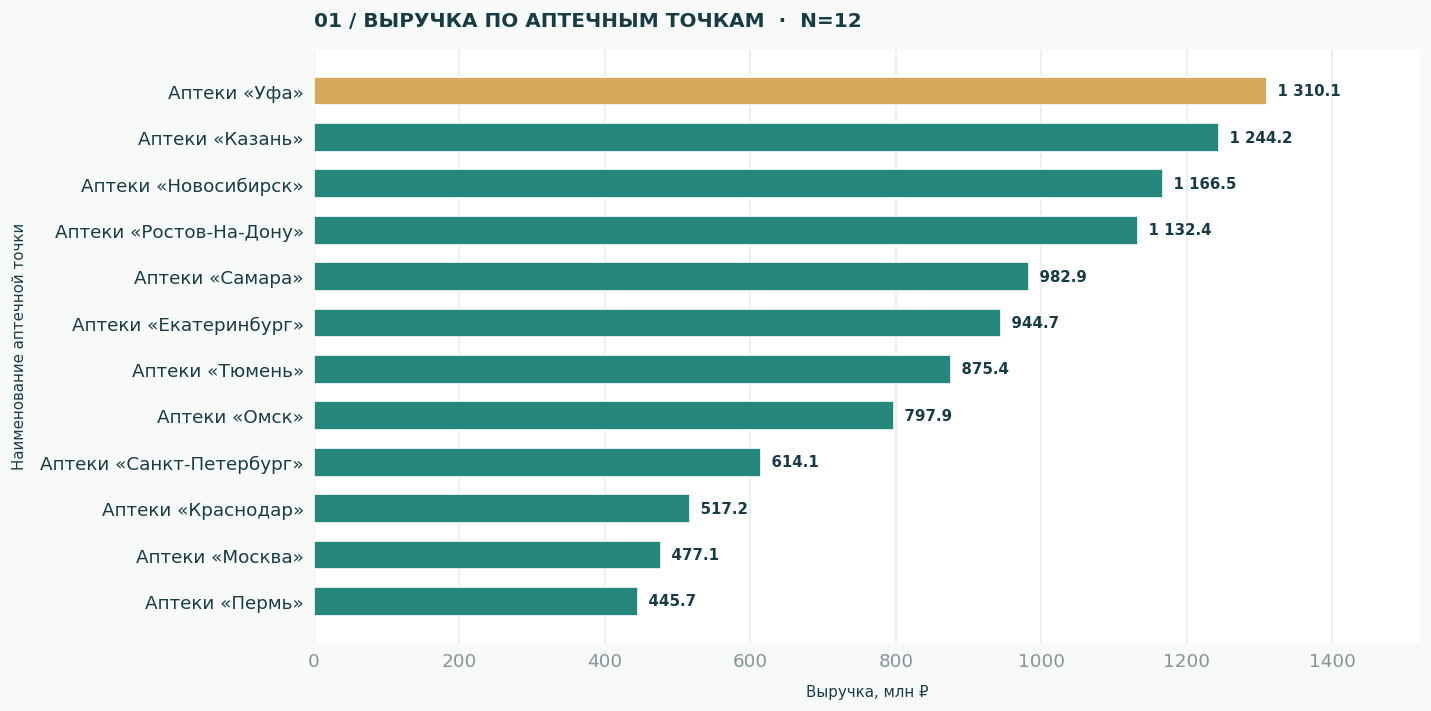

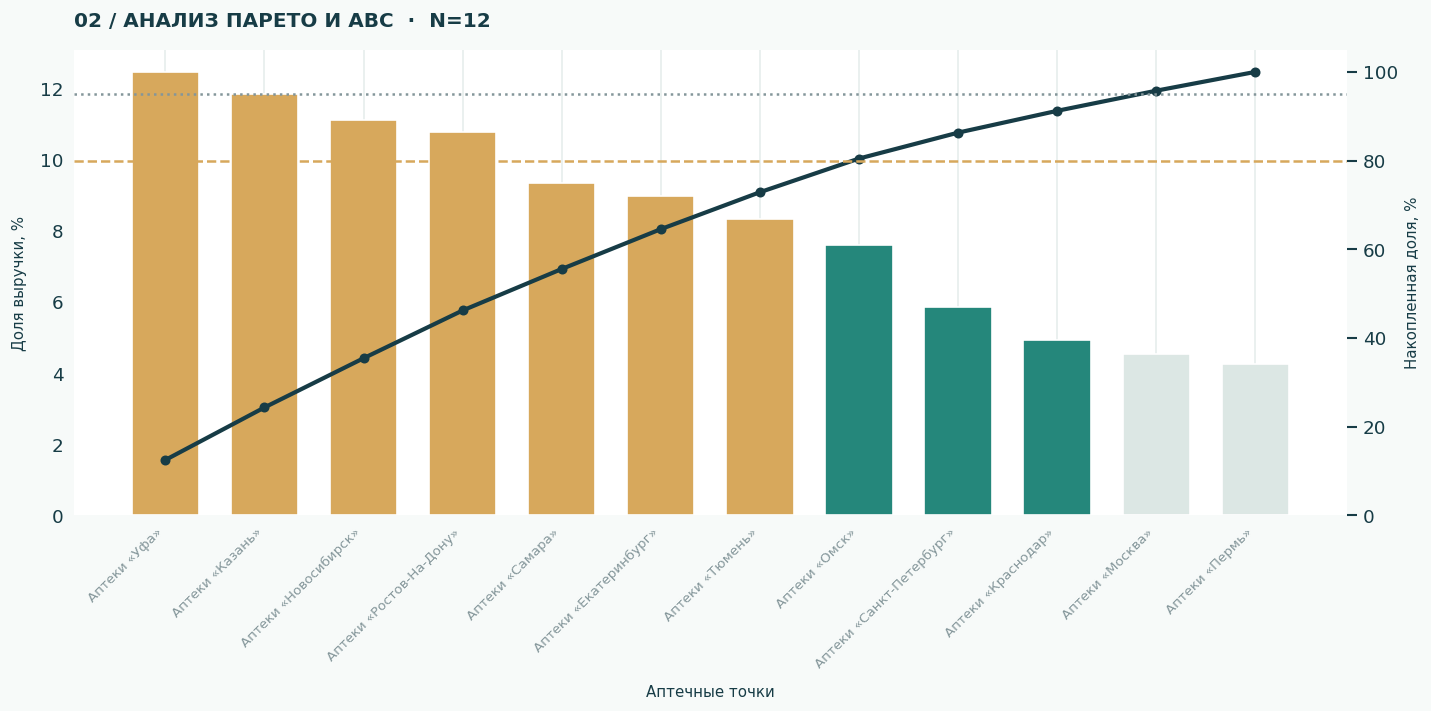

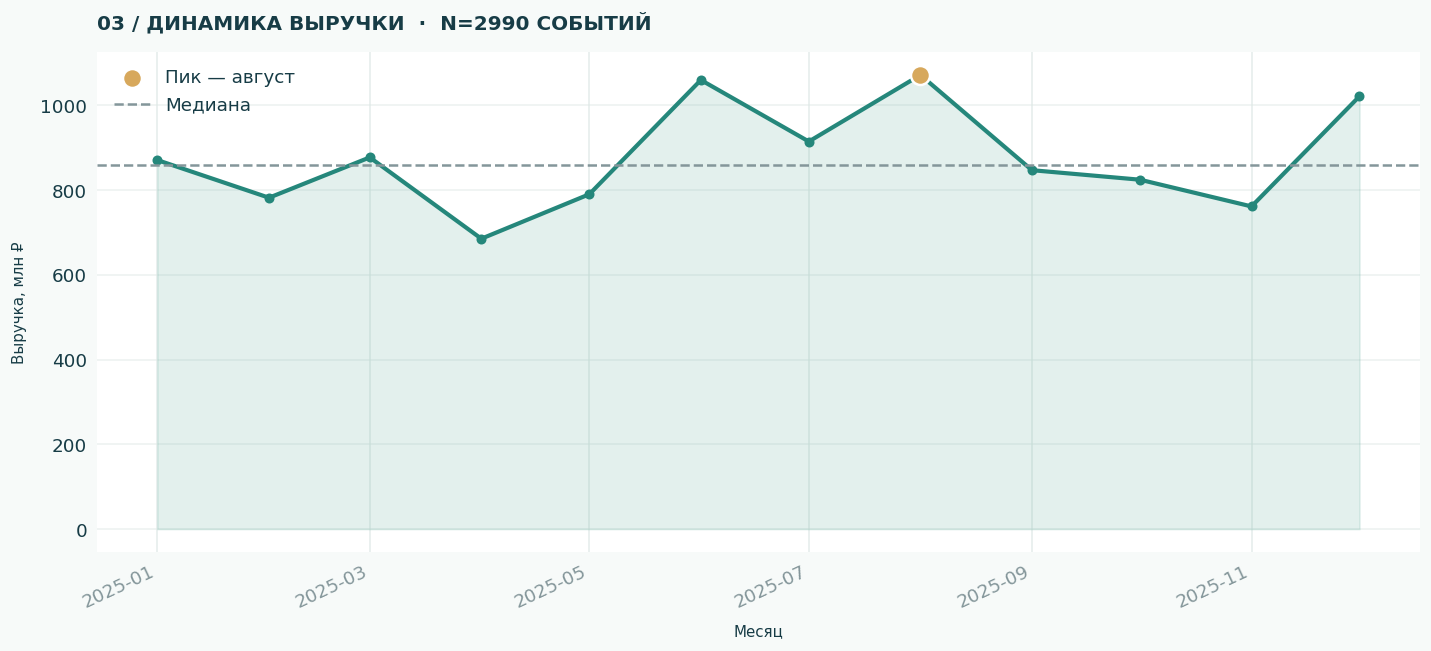

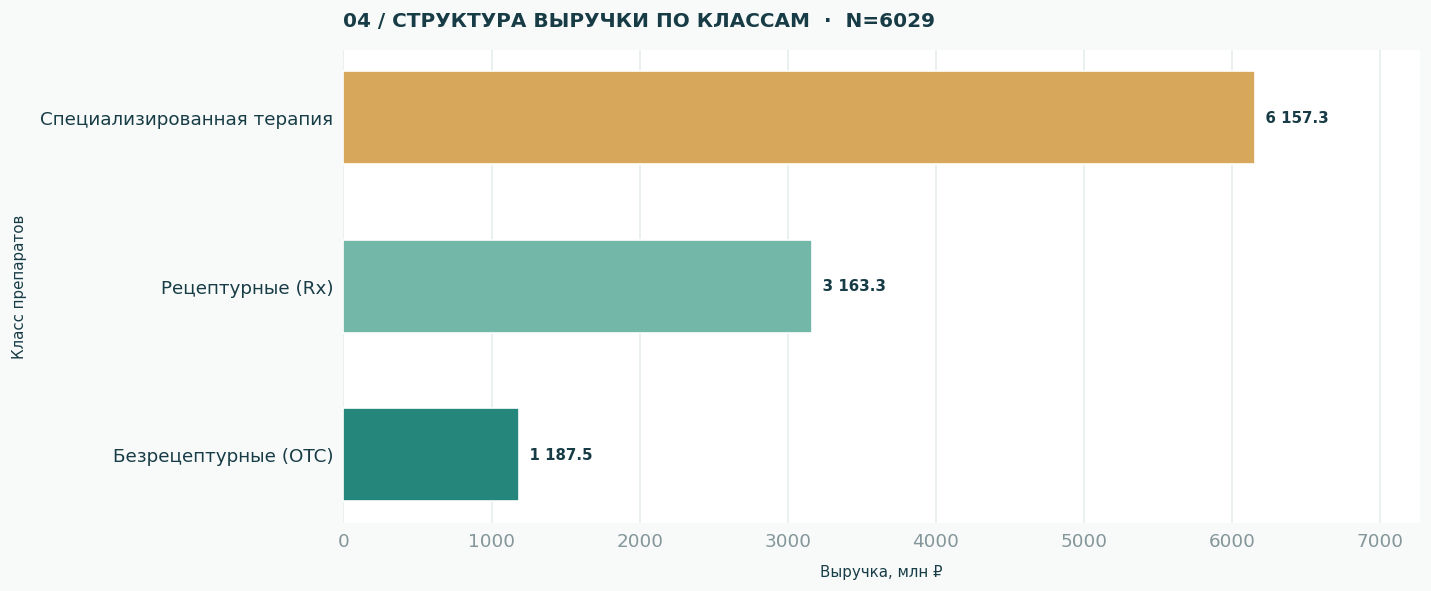

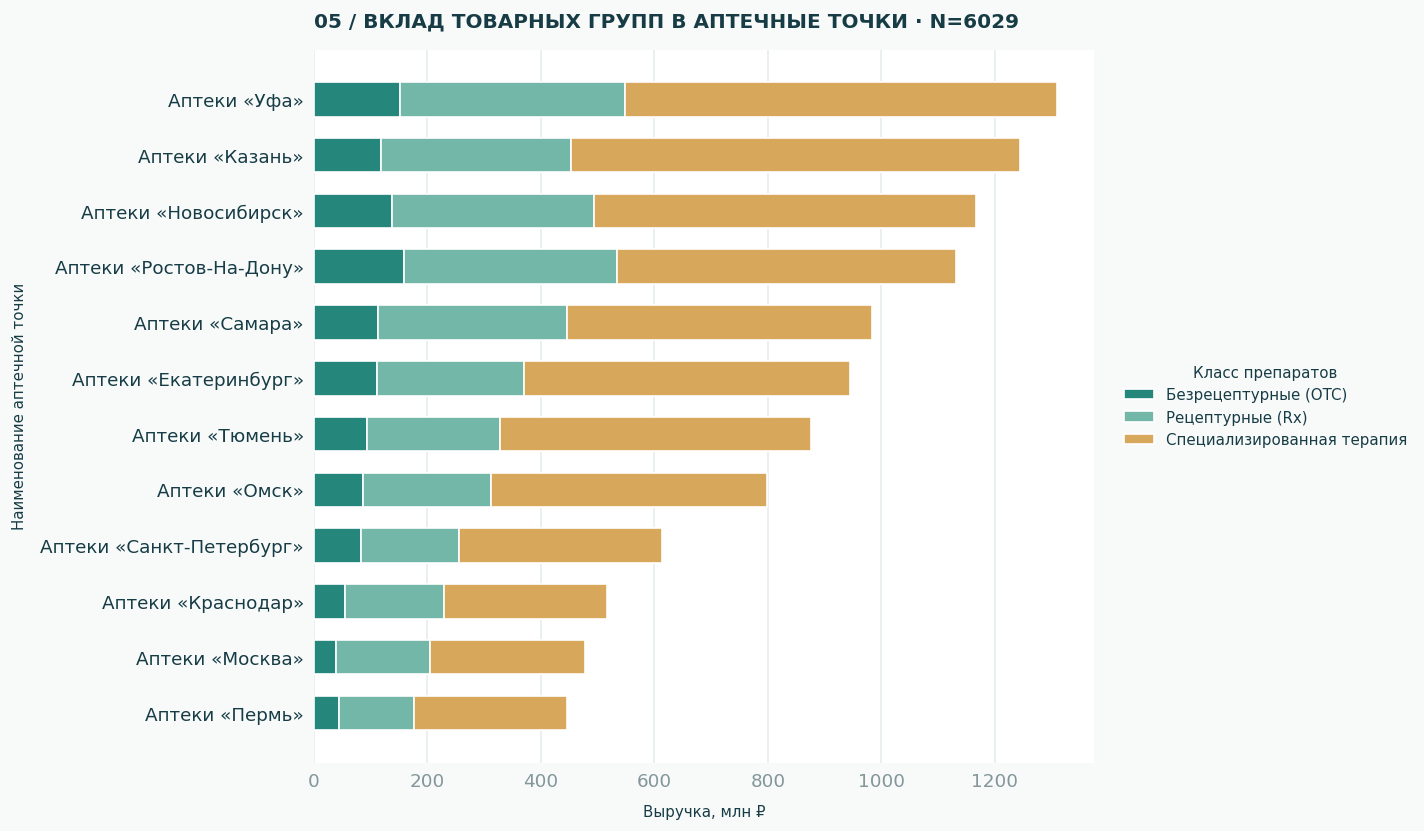

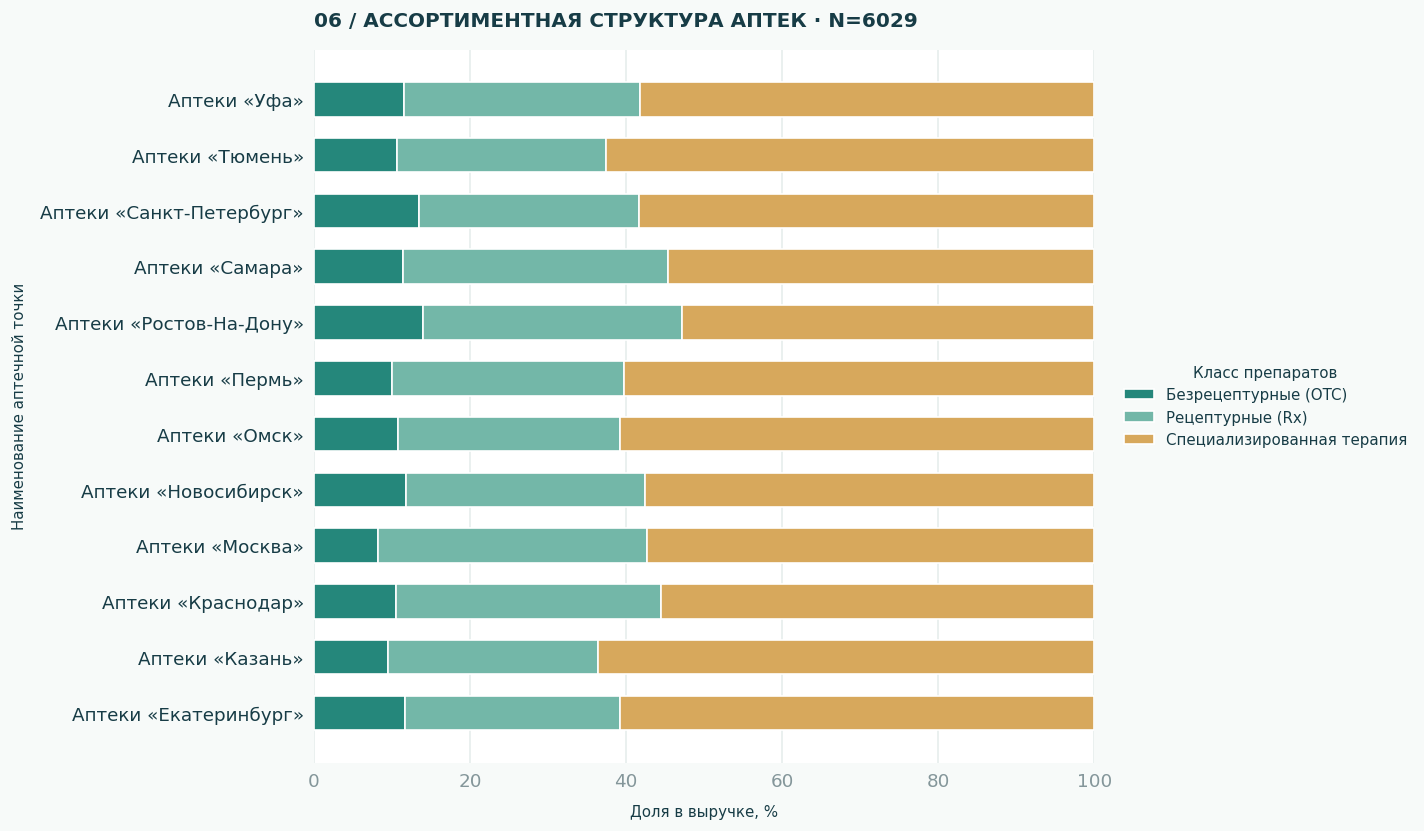


================== ВЫВОДЫ ДЛЯ ЛПР ==================

Предметная область: Аптечные сети (вариант 24)

Объём данных:
- Аптечных точек: 12
- Событий продаж: 2990
- Строк с ценами: 6029
- Строк в карантине: 45
- Доля строк в карантине: 0.50%

Итоговая выручка: 10 508 153 385 ₽

1. КОНЦЕНТРАЦИЯ ВЫРУЧКИ
Три крупнейшие аптечные точки формируют 35.4% общей выручки сети.
Лидер: Аптеки «Уфа».
Его доля в общей выручке составляет 12.5%.
По результатам ABC-анализа группа A включает 7 аптечных точек.


2. ВКЛАД ТОВАРНЫХ ГРУПП
Наибольший вклад в выручку обеспечивает категория «Специализированная терапия».
Её доля составляет 58.6% от общей выручки.
Анализ entity_id × price_class позволяет определить, какие аптечные точки специализируются на отдельных категориях препаратов, а какие имеют более равномерную структуру продаж.

3. СЕЗОННОСТЬ
Соотношение максимальной и минимальной месячной выручки составляет 1.56 раза.
Пиковый месяц: август.
При планировании закупок и персонала необходимо учитывать выявле

In [51]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
# Постройте четыре графика:
#   1) выручка по субъектам с выделением лидера;
#   2) диаграмма Парето с накопленной долей и группами ABC (порог 80 % и 95 %);
#   3) помесячная динамика выручки с отметкой пика и медианы;
#   4) структура выручки по разрезу цен (CFG["cls"]).
# Требования: заголовок с объёмом выборки, подписи осей с единицами, единая палитра,
# один акцентный цвет на выделяемый объект.

# Аналитическая задача из варианта (24): Вклад товарных групп и сравнение точек.
# Комментарий от Тимура Муртазовича с почты: Для задачи «вклад товарных групп и сравнение точек» используйте price_class и entity_id, а канал продаж и смену можно взять как дополнительный срез.

PLOT_FIGURES = []

#Общий стиль

# Палитра (желто-зеленый стиль)
DARK = "#173C46"
TEAL = "#25877B"
MINT = "#73B7A8"
GOLD = "#D7A85C"
LIGHT = "#DCE7E4"
GREY = "#84969A"
BG = "#F7FAF9"
WHITE = "#FFFFFF"

# Цвета товарных групп
CLASS_COLORS = {
    "Безрецептурные (OTC)": TEAL,
    "Рецептурные (Rx)": MINT,
    "Специализированная терапия": GOLD
}

# Глобальные параметры
plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": WHITE,
    "axes.edgecolor": LIGHT,
    "axes.labelcolor": DARK,
    "text.color": DARK,
    "xtick.color": GREY,
    "ytick.color": DARK,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelsize": 9,
    "font.size": 9,
    "grid.color": LIGHT,
    "grid.alpha": 0.8,
    "grid.linestyle": "-",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "legend.frameon": False,
    "figure.dpi": 120
})

def style_ax(ax, title, xlabel=None, ylabel=None):
    ax.set_title(
        title,
        loc="left",
        pad=14,
        color=DARK,
        fontsize=12,
        fontweight="bold"
    )

    if xlabel:
        ax.set_xlabel(xlabel, labelpad=8)

    if ylabel:
        ax.set_ylabel(ylabel, labelpad=8)

    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.7)
    ax.tick_params(length=0, pad=6)


def clean_number(value):
    return f"{value:,.1f}".replace(",", " ")

#Подготовка срезов:
# Выручка по аптечным точкам
top = (
    revenue_sql
    .sort_values("revenue", ascending=True)
    .reset_index(drop=True)
)

# Данные для Парето
pareto = (
    revenue_sql
    .sort_values("revenue", ascending=False)
    .copy()
)

# Общая выручка
total_revenue = float(revenue_sql["revenue"].sum())

# Доля каждой аптеки
pareto["доля"] = pareto["revenue"] / total_revenue

# Накопленная доля
pareto["накопленная доля"] = pareto["доля"].cumsum()

# ABC-анализ
pareto["группа ABC"] = np.where(
    pareto["накопленная доля"] <= 0.80,
    "A",
    np.where(pareto["накопленная доля"] <= 0.95, "B", "C")
)

# Количество аптек
n_entities = len(revenue_sql)

# Количество аптек группы A
n_a = int((pareto["группа ABC"] == "A").sum())

# Помесячная динамика выручки

events_month = events_valid.copy()

events_month["month"] = (
    pd.to_datetime(events_month["event_date"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly = (
    events_month
    .merge(
        price_per_event_pd,
        on="event_id",
        how="inner"
    )
    .assign(
        revenue=lambda x: x["volume_units"] * x["avg_price"]
    )
    .groupby("month", as_index=False)["revenue"]
    .sum()
    .sort_values("month")
)

# Пиковый месяц
peak = monthly.loc[monthly["revenue"].idxmax()]

# Медианная месячная выручка
median_revenue = monthly["revenue"].median()

# Количество событий
n_events = events_valid["event_id"].nunique()


def ru_month(date):
    months = [
        "январь", "февраль", "март", "апрель",
        "май", "июнь", "июль", "август",
        "сентябрь", "октябрь", "ноябрь", "декабрь"
    ]
    return months[pd.Timestamp(date).month - 1]

# Данные для анализа товарных групп

class_data = (
    prices_valid[
        ["event_id", "price_class", "unit_price"]
    ]
    .merge(
        events_valid[
            ["event_id", "entity_id", "volume_units"]
        ],
        on="event_id",
        how="inner"
    )
)

# Средняя цена события
class_data["avg_price"] = (
    class_data.groupby("event_id")["unit_price"]
    .transform("mean")
)

# Количество ценовых строк события
class_data["n_rows"] = (
    class_data.groupby("event_id")["event_id"]
    .transform("count")
)

# Количество ценовых записей
n_prices = len(prices_valid)

# Выручка по строкам цен
# Примечание для проверяющего. В рамках подсчета выручки по строкам предполагается, что объём события равномерно распределяется между всеми ценовыми строками для обеспечения сходимости с общей выручкой. Связано допущение с отсутствием в синтетических данных информации по количеству проданных упаковок по каждому классу. При работе не с синтетическими, а с реальными данными необходимо было бы запросить дополнительную информацию по количеству проданных упаковок.
class_data["revenue"] = (
    class_data["volume_units"]
    * class_data["unit_price"]
    / class_data["n_rows"]
)
print ('Примечание для проверяющего. В рамках подсчета выручки по строкам (class_data["revenue"] ) предполагается, что объём равномерно распределяется между всеми ценовыми строками для обеспечения сходимости с общей выручкой. Связано допущение с отсутствием в синтетических данных информации по количеству проданных упаковок по каждому классу. При работе не с синтетическими, а с реальными данными необходимо было бы запросить дополнительную информацию по количеству проданных упаковок.')
# Выручка по классам препаратов
by_class = (
    class_data
    .groupby("price_class", as_index=False)["revenue"]
    .sum()
    .sort_values("revenue", ascending=False)
)

class_plot = by_class.sort_values(
    "revenue",
    ascending=True
)
# Сводная таблица: аптеки и товарные группы

pivot_class = (
    class_data
    .pivot_table(
        index="entity_id",
        columns="price_class",
        values="revenue",
        aggfunc="sum",
        fill_value=0
    )
)

pivot_class["Итого"] = pivot_class.sum(axis=1)

price_classes = [
    col for col in pivot_class.columns
    if col != "Итого"
]

# Объединяем с названиями аптек
pivot_plot = (
    pivot_class
    .reset_index()
    .merge(
        entities[["entity_id", "entity_name"]],
        on="entity_id",
        how="left"
    )
    .sort_values("Итого", ascending=True)
    .set_index("entity_name")
)

# Доли товарных групп в выручке аптек
class_share = (
    pivot_class[price_classes]
    .div(
        pivot_class["Итого"].replace(0, np.nan),
        axis=0
    )
    .fillna(0) * 100
)

class_share_plot = (
    class_share
    .reset_index()
    .merge(
        entities[["entity_id", "entity_name"]],
        on="entity_id",
        how="left"
    )
    .sort_values("entity_name")
    .set_index("entity_name")
)

# Выручка по каналам продаж

channel_data = (
    consolidated
    .groupby("sales_channel", as_index=False)["event_revenue"]
    .sum()
    .rename(columns={"event_revenue": "revenue"})
    .sort_values("revenue", ascending=False)
)

# Выручка по сменам

shift_data = (
    consolidated
    .groupby("shift", as_index=False)["event_revenue"]
    .sum()
    .rename(columns={"event_revenue": "revenue"})
    .sort_values("revenue", ascending=False)
)

best_channel = channel_data.iloc[0]
best_shift = shift_data.iloc[0]

# Контроль сходимости аналитических разрезов

# Эталонная сумма — корректная выручка из SQL
reference_revenue = float(
    revenue_sql["revenue"].sum()
)

TOLERANCE = 0.05  # допустимое расхождение, рубли (выбрала 5 копеек, т.к. из-за особенностей выполнения арифметических действий с числами с плавающей точкой могут быть незначительные погрешности)

# Словарь аналитических разрезов
slices = {
    "По аптечным точкам":
        revenue_sql["revenue"].sum(),

    "По месяцам":
        monthly["revenue"].sum(),

    "По товарным группам":
        by_class["revenue"].sum(),

    "По каналам продаж":
        channel_data["revenue"].sum(),

    "По сменам":
        shift_data["revenue"].sum(),

    "Аптеки и товарные группы":
        pivot_class[price_classes].to_numpy().sum()
}

# Формируем таблицу контроля
convergence_results = []

for name, value in slices.items():

    value = float(value)

    difference = value - reference_revenue

    passed = abs(difference) <= TOLERANCE

    convergence_results.append({
        "Аналитический разрез": name,
        "Выручка, ₽": value,
        "Расхождение, ₽": difference,
        "Статус": "OK" if passed else "ОШИБКА"
    })

convergence_df = pd.DataFrame(
    convergence_results
)

print("КОНТРОЛЬ СХОДИМОСТИ АНАЛИТИЧЕСКИХ РАЗРЕЗОВ")

display(
    convergence_df.style.format({
        "Выручка, ₽": "{:,.2f}",
        "Расхождение, ₽": "{:,.4f}"
    })
)

# Отдельная проверка по каждой аптеке
class_by_entity = (
    pivot_class[price_classes]
    .sum(axis=1)
)

entity_reference = (
    revenue_sql
    .set_index("entity_id")["revenue"]
)

entity_check = pd.concat(
    [
        entity_reference.rename("Выручка SQL"),
        class_by_entity.rename("Выручка по классам")
    ],
    axis=1
)

entity_check["Расхождение"] = (
    entity_check["Выручка по классам"]
    - entity_check["Выручка SQL"]
)

assert (
    entity_check["Расхождение"].abs()
    <= TOLERANCE
).all(), "Ошибка: выручка по товарным группам не сходится по аптекам"

# Проверка всех аналитических разрезов
assert (
    convergence_df["Статус"] == "OK"
).all(), "Ошибка: аналитические разрезы не сходятся с итоговой выручкой"

print("\nВсе аналитические разрезы проверены.")
print("Выручка по каждому разрезу совпадает с итоговой.")
print("Расхождение не превышает допустимую погрешность.")

# ГРАФИК 1. ВЫРУЧКА ПО АПТЕКАМ

fig, ax = plt.subplots(figsize=(12, 6))

colors = [
    GOLD if i == len(top)-1 else TEAL
    for i in range(len(top))
]

bars = ax.barh(
    top["entity_name"],
    top["revenue"] / 1e6,
    color=colors,
    height=0.62
)

for bar, value in zip(
    bars,
    top["revenue"] / 1e6
):
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f"  {clean_number(value)}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

style_ax(
    ax,
    f"01 / ВЫРУЧКА ПО АПТЕЧНЫМ ТОЧКАМ  ·  N={n_entities}",
    "Выручка, млн ₽",
    "Наименование аптечной точки"
)

ax.grid(axis="y", visible=False)
ax.margins(x=0.16)

plt.tight_layout()
plt.show()

# ГРАФИК 2. ПАРЕТО И ABC

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(pareto))

abc_colors = {
    "A": GOLD,
    "B": TEAL,
    "C": LIGHT
}

ax.bar(
    x,
    pareto["доля"] * 100,
    color=[
        abc_colors[g]
        for g in pareto["группа ABC"]
    ],
    width=0.68
)

ax.set_xticks(x)
ax.set_xticklabels(
    pareto["entity_name"],
    rotation=45,
    ha="right",
    fontsize=8
)

ax.set_ylabel("Доля в выручке, %")

ax2 = ax.twinx()

ax2.plot(
    x,
    pareto["накопленная доля"] * 100,
    color=DARK,
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax2.axhline(
    80,
    color=GOLD,
    linestyle="--",
    linewidth=1.5
)

ax2.axhline(
    95,
    color=GREY,
    linestyle=":",
    linewidth=1.5
)

ax2.set_ylim(0, 105)
ax2.set_ylabel("Накопленная доля, %")

style_ax(
    ax,
    f"02 / АНАЛИЗ ПАРЕТО И ABC  ·  N={n_entities}",
    "Аптечные точки",
    "Доля выручки, %"
)

ax.grid(axis="y", visible=False)
ax2.grid(False)

plt.tight_layout()
plt.show()

# ГРАФИК 3. ПОМЕСЯЧНАЯ ДИНАМИКА

fig, ax = plt.subplots(figsize=(12, 5.5))

x_dates = monthly["month"]
y_values = monthly["revenue"] / 1e6

ax.fill_between(
    x_dates,
    y_values,
    color=MINT,
    alpha=0.20
)

ax.plot(
    x_dates,
    y_values,
    color=TEAL,
    linewidth=2.5,
    marker="o",
    markersize=5
)

ax.scatter(
    peak["month"],
    peak["revenue"] / 1e6,
    color=GOLD,
    edgecolor=WHITE,
    linewidth=1.5,
    s=130,
    zorder=5,
    label=f"Пик — {ru_month(peak['month'])}"
)

ax.axhline(
    median_revenue / 1e6,
    color=GREY,
    linestyle="--",
    linewidth=1.5,
    label="Медиана"
)

style_ax(
    ax,
    f"03 / ДИНАМИКА ВЫРУЧКИ  ·  N={n_events} СОБЫТИЙ",
    "Месяц",
    "Выручка, млн ₽"
)

ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.5)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# ГРАФИК 4. СТРУКТУРА ПО КЛАССАМ ЦЕН

# Распределяем выручку события между строками цен

fig, ax = plt.subplots(figsize=(12, 5))

colors = [
    CLASS_COLORS.get(c, GREY)
    for c in class_plot["price_class"]
]

bars = ax.barh(
    class_plot["price_class"],
    class_plot["revenue"] / 1e6,
    color=colors,
    height=0.55
)

for bar in bars:
    ax.text(
        bar.get_width(),
        bar.get_y() + bar.get_height()/2,
        f"  {clean_number(bar.get_width())}",
        va="center",
        fontweight="bold"
    )

style_ax(
    ax,
    f"04 / СТРУКТУРА ВЫРУЧКИ ПО КЛАССАМ  ·  N={n_prices}",
    "Выручка, млн ₽",
    "Класс препаратов"
)

ax.grid(axis="y", visible=False)
ax.margins(x=0.18)

plt.tight_layout()
plt.show()

# ГРАФИК 5. ВКЛАД ГРУПП В КАЖДУЮ АПТЕКУ
# Сводная таблица: выручка по аптекам и классам цен

fig, ax = plt.subplots(figsize=(12, 7))
n_price_rows = len(prices_valid)
pivot_plot = (
    pivot_class
    .reset_index()
    .merge(
        entities[["entity_id", "entity_name"]],
        on="entity_id",
        how="left"
    )
    .sort_values("Итого", ascending=True)
    .set_index("entity_name")
)

left = np.zeros(len(pivot_plot))

for cls in price_classes:

    values = pivot_plot[cls].values / 1e6

    ax.barh(
        pivot_plot.index,
        values,
        left=left,
        color=CLASS_COLORS.get(cls, GREY),
        label=cls,
        height=0.62
    )

    left += values

style_ax(
    ax,
    f"05 / ВКЛАД ТОВАРНЫХ ГРУПП В АПТЕЧНЫЕ ТОЧКИ · N={n_price_rows}",
    "Выручка, млн ₽",
    "Наименование аптечной точки"
)

ax.legend(
    title="Класс препаратов",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=9
)

ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()

# ГРАФИК 6. СТРУКТУРА ПРОДАЖ ПО АПТЕКАМ, %

fig, ax = plt.subplots(figsize=(12, 7))

left = np.zeros(len(class_share_plot))

for cls in price_classes:

    values = class_share_plot[cls].values

    ax.barh(
        class_share_plot.index,
        values,
        left=left,
        color=CLASS_COLORS.get(cls, GREY),
        label=cls,
        height=0.62
    )

    left += values

style_ax(
    ax,
    f"06 / АССОРТИМЕНТНАЯ СТРУКТУРА АПТЕК · N={n_price_rows}",
    "Доля в выручке, %",
    "Наименование аптечной точки"
)

ax.set_xlim(0, 100)
ax.legend(
    title="Класс препаратов",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=9
)

ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()
PLOTS_DONE = True

# ------------------------------------------------------------------ TODO 6.2
# Сформируйте выводы для ЛПР: концентрация выручки, сезонность, влияние качества данных
# (коэффициент завышения из шага 5) и три рекомендации с ожидаемым эффектом.

leader = pareto.iloc[0]

share_top3 = float(
    pareto["доля"].head(3).sum()
)

season_gap = (
    float(monthly["revenue"].max())
    / max(float(monthly["revenue"].min()), 0.000001)
)

# Доля крупнейшей товарной группы
top_class = by_class.iloc[0]

top_class_share = (
    top_class["revenue"] / total_revenue
)

# Определяем наиболее доходный канал
best_channel = channel_data.iloc[0]

# Определяем наиболее доходную смену
best_shift = shift_data.iloc[0]

# Качество данных
lost_rows = (
    len(quarantine_fk)
    + len(quarantine_price)
    + len(quarantine_events)
)

lost_share = (
    lost_rows /
    max(len(raw_events) + len(raw_prices), 1)
)

print(f"""
================== ВЫВОДЫ ДЛЯ ЛПР ==================

Предметная область: Аптечные сети (вариант 24)

Объём данных:
- Аптечных точек: {n_entities}
- Событий продаж: {n_events}
- Строк с ценами: {n_prices}
- Строк в карантине: {lost_rows}
- Доля строк в карантине: {lost_share:.2%}

Итоговая выручка: {nf(total_revenue)} ₽

1. КОНЦЕНТРАЦИЯ ВЫРУЧКИ
Три крупнейшие аптечные точки формируют {share_top3:.1%} общей выручки сети.
Лидер: {leader['entity_name']}.
Его доля в общей выручке составляет {leader['доля']:.1%}.
По результатам ABC-анализа группа A включает {n_a} аптечных точек.


2. ВКЛАД ТОВАРНЫХ ГРУПП
Наибольший вклад в выручку обеспечивает категория «{top_class['price_class']}».
Её доля составляет {top_class_share:.1%} от общей выручки.
Анализ entity_id × price_class позволяет определить, какие аптечные точки специализируются на отдельных категориях препаратов, а какие имеют более равномерную структуру продаж.

3. СЕЗОННОСТЬ
Соотношение максимальной и минимальной месячной выручки составляет {season_gap:.2f} раза.
Пиковый месяц: {ru_month(peak['month'])}.
При планировании закупок и персонала необходимо учитывать выявленные колебания спроса.

4. КАНАЛЫ ПРОДАЖ И СМЕНЫ

Наиболее доходный канал продаж: {best_channel['sales_channel']}.
Выручка канала: {nf(best_channel['revenue'])} ₽.
Наиболее доходная смена: {best_shift['shift']}.
Выручка смены: {nf(best_shift['revenue'])} ₽.
Эти показатели могут использоваться для дополнительной оптимизации работы аптек.

5. ВЛИЯНИЕ КАЧЕСТВА ДАННЫХ

Наивный SQL-запрос завышал выручку в {overstate:.2f} раза.
Причина — размножение строк при JOIN таблиц events и prices (fan-out).
Использование некорректной методики привело бы к завышению финансовых показателей и ошибочным управленческим решениям.

====================================================

ВАЖНЫЕ УТОЧНЕНИЯ:
При интерпретации результатов необходимо учитывать следующие ограничения:

1. Учебный характер данных. Исходные наборы данных сгенерированы программно и содержат искусственно внесённые дефекты. Поэтому полученные результаты демонстрируют методику консолидации и анализа, но не являются фактической характеристикой реальной аптечной сети.

2. Упрощённая методика расчёта цены. Для каждого события используется средняя арифметическая цена связанных записей. При отсутствии информации о количестве проданных единиц по каждому классу препаратов невозможно рассчитать фактическую взвешенную цену и достоверно определить вклад каждой товарной группы.

3. Ограниченность ассортиментной аналитики. Распределение выручки по товарным группам выполняется посредством равномерного распределения выручки события между ценовыми строками. Поэтому полученные доли используются для предварительной аналитической оценки, а не для окончательных решений о закупках.

4. Отсутствие данных о себестоимости и прибыли. Анализируется выручка, но не рассчитывается валовая прибыль, рентабельность и маржинальность аптечных точек. Высокая выручка не обязательно означает высокую прибыльность.

5. Отсутствие данных об остатках и спросе. Невозможно непосредственно оценить оборачиваемость запасов, уровень дефицита препаратов и упущенные продажи. Поэтому рекомендации по закупкам требуют дополнительной проверки на основании товарного учёта.

Таким образом, результаты исследования позволяют оценить структуру выручки, сравнить аптечные точки и продемонстрировать методику корректной обработки данных. Для принятия окончательных управленческих решений необходимо дополнить модель данными о фактических продажах по товарным группам, себестоимости, остатках и движении товарных запасов.

""")

# УПРАВЛЕНЧЕСКИЕ РЕКОМЕНДАЦИИ ДЛЯ АПТЕЧНОЙ СЕТИ

# 1. Подготовка показателей

# Общая выручка
total_revenue = float(revenue_sql["revenue"].sum())

# Выручка и доля каждой аптеки
entity_analysis = revenue_sql.copy()

entity_analysis["revenue_share"] = (
    entity_analysis["revenue"] / total_revenue * 100
)

entity_analysis["revenue_per_event"] = (
    entity_analysis["revenue"]
    / entity_analysis["events_cnt"].replace(0, np.nan)
)

# Три крупнейшие аптеки
top3_entities = (
    entity_analysis
    .sort_values("revenue", ascending=False)
    .head(3)
)

# Две аптеки с минимальной выручкой
bottom2_entities = (
    entity_analysis
    .sort_values("revenue", ascending=True)
    .head(2)
)

# Доля трёх крупнейших аптек
share_top3 = (
    top3_entities["revenue"].sum()
    / total_revenue * 100
)

# Лидер сети
leader = top3_entities.iloc[0]

# Средняя выручка на событие у лидера
leader_avg = leader["revenue_per_event"]

# Количество аптек группы A
n_a = int(
    (pareto["группа ABC"] == "A").sum()
)

# 2. Анализ товарных групп

# Наиболее доходная товарная группа
top_class = (
    by_class
    .sort_values("revenue", ascending=False)
    .iloc[0]
)

top_class_name = top_class["price_class"]
top_class_revenue = float(top_class["revenue"])

top_class_share = (
    top_class_revenue / total_revenue * 100
)

# Доля остальных товарных групп
other_classes_share = 100 - top_class_share

# Находим аптеку с максимальной выручкой по ведущей товарной группе

class_entity_analysis = (
    pivot_class[[top_class_name]]
    .reset_index()
    .merge(
        entities[["entity_id", "entity_name"]],
        on="entity_id",
        how="left"
    )
    .sort_values(top_class_name, ascending=False)
)

class_leader = class_entity_analysis.iloc[0]

class_leader_share = (
    class_leader[top_class_name]
    / top_class_revenue * 100
)

# 3. Анализ сезонности

peak_month = monthly.loc[
    monthly["revenue"].idxmax()
]

min_month = monthly.loc[
    monthly["revenue"].idxmin()
]

season_gap = (
    peak_month["revenue"]
    / min_month["revenue"]
)

# Медианная месячная выручка
median_revenue = float(
    monthly["revenue"].median()
)

# 4. Коэффициент завышения наивного JOIN

if "overstate" not in globals():
    overstate = (
        compare["revenue_naive"].sum()
        / compare["revenue"].sum()
    )

# 5. Форматирование

def fmt_rub(value):
    return f"{nf(value, 2)} ₽"

def fmt_bln(value):
    return f"{value / 1e9:.2f}".replace(".", ",") + " млрд ₽"

def fmt_mln(value):
    return f"{value / 1e6:.1f}".replace(".", ",") + " млн ₽"


print("""
====================================================
   РЕКОМЕНДАЦИИ ДЛЯ РУКОВОДСТВА АПТЕЧНОЙ СЕТИ
""")

# ------------------------------------------------------------
# РЕКОМЕНДАЦИЯ 1. СРАВНЕНИЕ АПТЕЧНЫХ ТОЧЕК
# ------------------------------------------------------------

print("1. ДИФФЕРЕНЦИРОВАТЬ УПРАВЛЕНИЕ АПТЕЧНЫМИ ТОЧКАМИ")
print()

print(
    f"Три крупнейшие аптечные точки формируют {share_top3:.1f}% общей выручки сети {fmt_bln(top3_entities['revenue'].sum())})."
)

print(
    f"Лидер — {leader['entity_name']}: {fmt_bln(leader['revenue'])},{leader['revenue_share']:.1f}% общей выручки, {int(leader['events_cnt'])} событий."
)

print(
    f"Средняя выручка на одно событие лидера: {fmt_rub(leader_avg)}."
)

print(
    f"По ABC-анализу в группу A входят {n_a} из {n_entities} аптечных точек."
)

print("\nДве точки с минимальной выручкой:")

for _, row in bottom2_entities.iterrows():
    print(
        f"- {row['entity_name']}: "
        f"{fmt_mln(row['revenue'])}; "
        f"{int(row['events_cnt'])} событий; "
        f"доля {row['revenue_share']:.1f}%."
    )

print("""
Предлагаемое решение: Для аптек группы A обеспечить приоритетный контроль доступности востребованных препаратов и регулярный мониторинг выручки.

Для аптек с минимальными показателями провести дополнительный анализ количества событий, средней выручки на событие, каналов продаж и товарной структуры.

Ожидаемый эффект: Повышение эффективности распределения управленческих ресурсов, выявление причин различий между точками и определение потенциала роста отстающих подразделений.

Контроль результата: Ежемесячно сравнивать выручку аптек, долю в общей выручке, количество событий и среднюю выручку на одно событие.
""")


# РЕКОМЕНДАЦИЯ 2. ТОВАРНЫЕ ГРУППЫ


print("\n2. ОПТИМИЗИРОВАТЬ АССОРТИМЕНТНУЮ ПОЛИТИКУ")
print()

print(
    f"Наибольший вклад в расчётную выручку обеспечивает категория «{top_class_name}»."
)

print(
    f"Её выручка составляет {fmt_bln(top_class_revenue)}, или {top_class_share:.1f}% общей выручки."
)

print(
    f"Остальные товарные группы формируют {other_classes_share:.1f}%."
)

print(
    f"Наибольшая расчётная выручка по данной категории зафиксирована в точке {class_leader['entity_name']}: {fmt_mln(class_leader[top_class_name])}."
)

print(
    f"Это {class_leader_share:.1f}% выручки данной товарной группы по сети."
)

print("""
Предлагаемое решение: Провести дополнительный анализ представленности ведущей товарной группы по каждой аптеке.

На основании фактических данных об остатках, продажах и сроках поставки определить минимальные страховые запасы востребованных препаратов.

Для аптек с недостаточной представленностью категории рассмотреть корректировку ассортимента и графиков поставок.

Ожидаемый эффект:
Снижение риска дефицита востребованных препаратов, повышение доступности ассортимента и сокращение потенциальных потерь выручки из-за отсутствия товара.

Контроль результата:
Ежемесячно отслеживать фактическую долю категории в продажах, уровень товарных запасов, случаи отсутствия препаратов и оборачиваемость остатков.

Ограничение:
Распределение выручки по ценовым классам основано на равномерном распределении выручки события между ценовыми строками. Поэтому полученная доля является
аналитической оценкой, а не подтверждённой долей фактических продаж категории.
""")

# РЕКОМЕНДАЦИЯ 3. СЕЗОННОСТЬ И КАЧЕСТВО РАСЧЁТОВ

print("\n3. ВНЕДРИТЬ СЕЗОННОЕ ПЛАНИРОВАНИЕ И КОНТРОЛЬ")
print()

print(
    f"Пиковый месяц по выручке — {ru_month(peak_month['month'])}: {fmt_mln(peak_month['revenue'])}."
)

print(
    f"Минимальная выручка зафиксирована в месяце {ru_month(min_month['month'])}: {fmt_mln(min_month['revenue'])}."
)

print(
    f"Отношение максимальной месячной выручки к минимальной составляет {season_gap:.2f} раза."
)

print(
    f"Медианная месячная выручка составляет {fmt_mln(median_revenue)}."
)

print(
    f"\nНаивный SQL JOIN завышает выручку в {overstate:.2f} раза."
)

print("""
Предлагаемое решение:
Использовать помесячную динамику выручки для формирования сезонного плана закупок и распределения персонала.

Перед периодами повышенной активности проводить проверку товарных остатков и доступности препаратов.

В финансовой отчётности закрепить обязательную предварительную агрегацию цен до уровня событияи автоматическую сверку SQL и pandas.

Ожидаемый эффект:
Повышение достоверности финансовой отчётности, снижение риска ошибок при расчёте выручки и более эффективное планирование закупок и персонала.

Контроль результата:
Ежемесячно сопоставлять фактическую выручку с плановой, контролировать отклонения по аптекам и месяцам, а также проверять совпадение результатов SQL и pandas.
""")

print("""
============================================================
                  ИТОГОВЫЙ ВЫВОД
============================================================
Управление аптечной сетью рекомендуется строить на сочетании ABC-анализа аптечных точек, контроля ассортиментной структуры и сезонного планирования.

При этом решения по товарным группам необходимо подтверждать фактическими данными о продажах и остатках, а финансовую отчётность формировать только на основе корректного расчёта выручки без эффекта fan-out.
============================================================
""")

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [52]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "pw2-consolidation-513220"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

Аутентификация в Colab выполнена
Датасет готов: pw2-consolidation-513220.pw2_consolidation (US)
  загружено entities: 12 строк
  загружено events: 2 990 строк
  загружено prices: 6 029 строк

Оценка объёма чтения: 0.17 МБ (бесплатный лимит — 1 ТБ в месяц)


,entity_name,events_cnt,revenue
0,Аптеки «Уфа»,392,"1,310,120,451.62"
1,Аптеки «Казань»,312,"1,244,239,263.90"
2,Аптеки «Новосибирск»,339,"1,166,523,403.46"
3,Аптеки «Ростов-На-Дону»,362,"1,132,365,088.96"
4,Аптеки «Самара»,282,"982,860,875.48"
5,Аптеки «Екатеринбург»,269,"944,661,508.60"
6,Аптеки «Тюмень»,231,"875,386,335.62"
7,Аптеки «Омск»,216,"797,897,330.50"
8,Аптеки «Санкт-Петербург»,193,"614,077,729.09"
9,Аптеки «Краснодар»,155,"517,223,769.56"


Максимальное расхождение BigQuery и SQLite: 0.0100


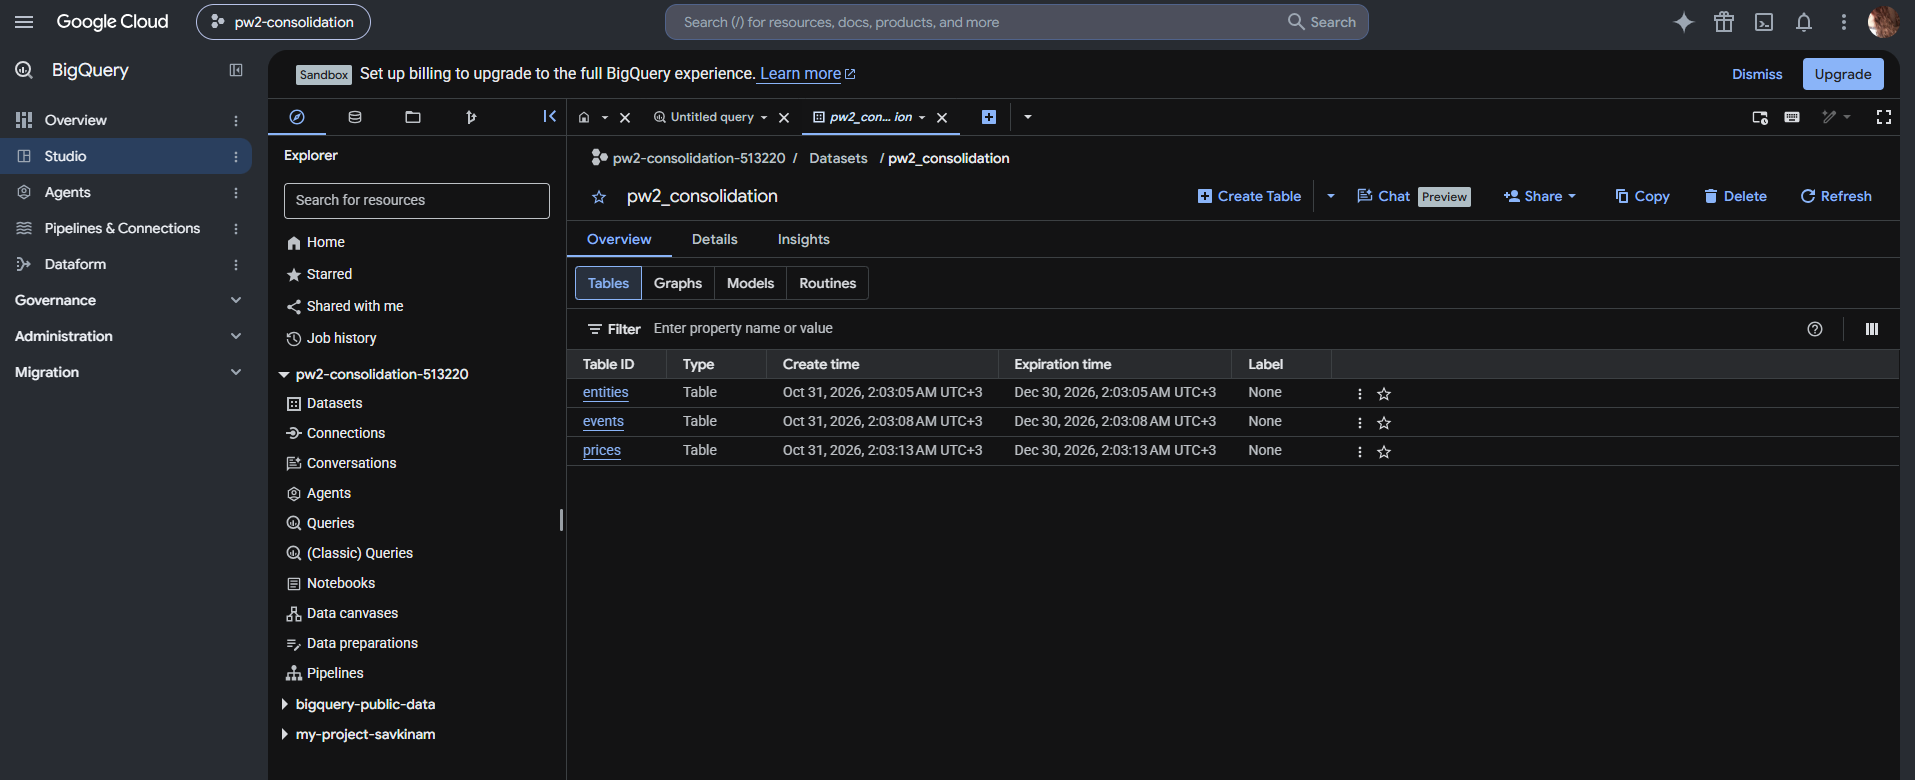

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

### Описательные столбцы событий и классы цен по вариантам

| № | Предметная область | Столбцы `events.xlsx` (кроме ключей, даты и объёма) | Классы цен в `prices.json` |
|---:|---|---|---|
| 1 | Авиаперевозки | `route`: «город — город»; `aircraft_type`: Узкофюзеляжный, Широкофюзеляжный, Региональный, Турбовинтовой | Эконом, Комфорт, Бизнес |
| 2 | Розничная сеть | `payment_method`: Наличные, Банковская карта, СБП, Карта + бонусы; `checkout_type`: Касса, Касса самообслуживания, Онлайн-заказ, Экспресс-касса | Бакалея, Бытовая химия, Электроника |
| 3 | Логистика | `route`: «город — город»; `vehicle_type`: Фура 20 т, Рефрижератор, Малотоннажный, Контейнеровоз | Базовый, Срочный, Экспресс |
| 4 | Телеком | `network`: 2G, 3G, 4G, 5G; `session_type`: Голос, Мобильный интернет, Роуминг, SMS-пакет | Базовый, Безлимитный, Корпоративный |
| 5 | Банковский ритейл | `service_channel`: Касса, Банкомат, Интернет-банк, Мобильное приложение; `client_segment`: Массовый, Зарплатный, Премиальный, МСБ | Переводы, Валютные операции, Инкассация |
| 6 | Гостиничный бизнес | `booking_channel`: Сайт отеля, Онлайн-агрегатор, Турагентство, Корпоративный договор; `guest_type`: Деловой, Туристический, Семейный, Групповой | Стандарт, Делюкс, Люкс |
| 7 | Образовательные услуги | `course_area`: IT, Иностранные языки, Управление, Подготовка к экзаменам; `audience`: Школьники, Студенты, Взрослые, Корпоративные клиенты | Онлайн, Смешанный, Очный |
| 8 | Медицинские клиники | `specialty`: Терапия, Педиатрия, Стоматология, Кардиология …; `payment_type`: ОМС, ДМС, Платно, Абонемент | Консультация, Диагностика, Процедура |
| 9 | Энергосбыт | `voltage_level`: ВН, СН-1, СН-2, НН; `contract_type`: Энергоснабжение, Купля-продажа, Регулируемый, Свободный рынок | Население, Бюджетные организации, Промышленность |
| 10 | Маркетплейс | `fulfillment`: Склад площадки, Склад продавца, Экспресс-доставка, Самовывоз; `order_channel`: Мобильное приложение, Сайт, Партнёрский сайт, Реклама в соцсетях | Товары для дома, Одежда, Электроника |
| 11 | Общественный транспорт | `line`: Маршрут 1, Маршрут 5, Маршрут 12, Маршрут 18 …; `vehicle_type`: Автобус, Трамвай, Троллейбус, Электробус | Разовый, Проездной на месяц, Проездной на год |
| 12 | Страхование | `client_type`: Физическое лицо, ИП, Малый бизнес, Крупный бизнес; `sales_channel`: Офис агентства, Онлайн, Банк-партнёр, Автосалон | ОСАГО, Имущество, КАСКО |
| 13 | Грузовые ж/д перевозки | `route`: «город — город»; `wagon_type`: Полувагон, Крытый вагон, Цистерна, Платформа | Уголь, Зерно, Нефтепродукты |
| 14 | Общепит | `service_format`: В зале, Навынос, Доставка, Банкет; `daypart`: Завтрак, Обед, Ужин, Поздний вечер | Напитки, Основные блюда, Фирменные сеты |
| 15 | Фитнес-сети | `visit_zone`: Тренажёрный зал, Бассейн, Групповые программы, Единоборства; `client_type`: Новый клиент, Постоянный, Корпоративный, Гостевой визит | Разовый, Месячный, Годовой |
| 16 | Аренда спецтехники | `site_type`: Жилое строительство, Дорожные работы, Промышленный объект, Коммунальные работы; `rental_mode`: С оператором, Без оператора, Долгосрочная, Почасовая | Мини-погрузчик, Экскаватор, Автокран |
| 17 | Курьерская доставка | `route`: «город — город»; `parcel_size`: Документы, Малая (S), Средняя (M), Крупная (L) | Стандарт, Ускоренная, Экспресс |
| 18 | Оптовая торговля | `client_channel`: Розничные сети, HoReCa, Независимая розница, Онлайн-ретейл; `delivery_mode`: Доставка дистрибьютора, Самовывоз, Транзит со склада, Кросс-докинг | Бакалея, Напитки, Кондитерские изделия |
| 19 | Автосервис | `car_class`: Отечественный, Иномарка эконом, Иномарка бизнес, Коммерческий транспорт; `visit_reason`: Плановое ТО, Ремонт, Шиномонтаж, Диагностика | Слесарные работы, Электрика и диагностика, Кузовные работы |
| 20 | Цифровые подписки | `platform`: iOS, Android, Веб, Smart TV; `acquisition`: Органика, Реклама, Промокод, Партнёр | Базовый, Стандарт, Премиум |
| 21 | Сельхозпроизводство | `buyer_type`: Элеватор, Перерабатывающий завод, Экспорт, Трейдер; `transport`: Автотранспорт, Железная дорога, Речной транспорт, Самовывоз | Пшеница, Подсолнечник, Соя |
| 22 | Строительный ритейл | `sales_channel`: Торговый зал, Интернет-магазин, Отдел для профи, Самовывоз со склада; `client_type`: Частный клиент, Бригада, Строительная компания, Дизайнер | Крепёж и расходники, Отделочные материалы, Инструмент |
| 23 | Морские перевозки | `route`: «порт — порт»; `cargo_mode`: Импорт, Экспорт, Транзит, Каботаж | 20' стандартный, 40' стандартный, 40' рефрижератор |
| 24 | Аптечные сети | `sales_channel`: Торговый зал, Онлайн-бронирование, Доставка, Корпоративный заказ; `shift`: Утренняя смена, Дневная смена, Вечерняя смена, Ночная смена | Безрецептурные (OTC), Рецептурные (Rx), Специализированная терапия |
| 25 | Кинотеатры | `hall`: Зал 1, Зал 2, Зал 3, Зал 4 …; `genre`: Анимация, Драма, Комедия, Фантастика | 2D, 3D, IMAX |
| 26 | Промышленное производство | `customer_type`: Дилер, Прямой клиент, Экспорт, Госзаказ; `shipping`: Железная дорога, Автотранспорт, Самовывоз, Контейнер | Марка М1, Марка М2, Марка М3 (премиум) |
| 27 | Рекламные площадки | `audience_age`: 18–24, 25–34, 35–44, 45+; `device`: Смартфон, Компьютер, Smart TV, Планшет | Баннер, Нативный, Видео |
| 28 | ЖКХ | `building_type`: Панельный дом, Кирпичный дом, Монолит, Новостройка; `payment_channel`: Банк, Госуслуги, Приложение УК, Касса УК | Содержание жилья, Водоснабжение, Отопление |
| 29 | Каршеринг | `trip_zone`: Центр, Спальный район, Аэропорт, Межгород; `client_type`: Новый, Постоянный, Корпоративный, Студенческий | Эконом, Комфорт, Премиум |
| 30 | Авиаперевозки (эталон преподавателя) | `route`: «город — город»; `aircraft_type`: Узкофюзеляжный, Широкофюзеляжный, Региональный, Турбовинтовой | Эконом, Комфорт, Бизнес |

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [53]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [54]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.

In [55]:

#@title C. Автотесты качества: остановка конвейера при ошибках
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.


#@title ★ C. Автотесты качества: проверка перед загрузкой { display-mode: "form" }

from IPython.display import display


def validate_clean_batch(entity_df, event_df, price_df):
    #Критичные проверки качества очищенных данных. При нарушении критичного правила AssertionError останавливает конвейер.

    # 1. Проверка наличия данных

    assert not entity_df.empty, "Справочник аптек пуст"
    assert not event_df.empty, "Таблица событий продаж пуста"
    assert not price_df.empty, "Таблица цен пуста"

    # 2. Проверка полноты и уникальности ключей
    for name, frame, key in [
        ("entities", entity_df, "entity_id"),
        ("events", event_df, "event_id"),
        ("prices", price_df, "price_id")
    ]:
        assert frame[key].notna().all(), (
            f"{name}: обнаружены пропущенные ключи"
        )

        assert frame[key].astype(str).str.strip().ne("").all(), (
            f"{name}: обнаружены пустые строковые ключи"
        )

        assert frame[key].is_unique, (
            f"{name}: обнаружены дубликаты первичного ключа"
        )

    # 3. Проверка обязательных полей

    assert entity_df["entity_name"].notna().all(), (
        "В справочнике аптек отсутствуют названия"
    )

    assert entity_df["entity_name"].astype(str).str.strip().ne("").all(), (
        "В справочнике аптек обнаружены пустые названия"
    )

    assert event_df[
        ["entity_id", "event_date", "volume_units"]
    ].notna().all().all(), (
        "В событиях продаж обнаружены пропущенные значения"
    )

    assert price_df[
        ["event_id", "unit_price"]
    ].notna().all().all(), (
        "В таблице цен обнаружены пропущенные значения"
    )

    # 4. Проверка типов и диапазонов значений

    parsed_dates = pd.to_datetime(
        event_df["event_date"], errors="coerce"
    )

    assert parsed_dates.notna().all(), (
        "Обнаружены нераспознанные даты событий"
    )

    volumes = pd.to_numeric(
        event_df["volume_units"], errors="coerce"
    ).to_numpy(dtype=float)

    unit_prices = pd.to_numeric(
        price_df["unit_price"], errors="coerce"
    ).to_numpy(dtype=float)

    assert np.isfinite(volumes).all() and (volumes > 0).all(), (
        "Обнаружены некорректные объёмы продаж"
    )

    assert np.isfinite(unit_prices).all() and (unit_prices > 0).all(), (
        "Обнаружены некорректные цены"
    )

    # 5. Проверка ссылочной целостности

    assert event_df["entity_id"].isin(
        entity_df["entity_id"]
    ).all(), (
        "Обнаружены события со ссылками на неизвестные аптеки"
    )

    assert price_df["event_id"].isin(
        event_df["event_id"]
    ).all(), (
        "Обнаружены цены со ссылками на неизвестные события"
    )


    # 6. Проверка экстремальных цен (некритичное правило)

    q1, q3 = np.quantile(unit_prices, [0.25, 0.75])
    iqr = q3 - q1

    flagged = int(
        (
            (unit_prices < q1 - 3 * iqr)
            | (unit_prices > q3 + 3 * iqr)
        ).sum()
    )

    if flagged:
        print(
            f"Внимание: обнаружено {flagged} экстремальных цен (метод 3 IQR). Необходимо проверить исходные данные."
        )

    print("Все критичные проверки качества данных пройдены.")

    return True

# 7. Запуск автотестов на очищенных данных

assert validate_clean_batch(
    entities,
    events_valid,
    prices_valid
)

print("\nАвтотесты качества данных успешно пройдены.")


# 8. Демонстрация остановки конвейера при ошибке

# Создаём копию таблицы цен, не изменяя исходные данные
_bad_prices = prices_valid.copy()

# Искусственно добавляем отрицательную цену
if not _bad_prices.empty:
    _bad_prices.loc[
        _bad_prices.index[0], "unit_price"
    ] = -1

    try:
        validate_clean_batch(
            entities,
            events_valid,
            _bad_prices
        )

        raise RuntimeError(
            "Ошибка: автотест пропустил отрицательную цену"
        )

    except AssertionError as exc:
        print(
            "\nКонтрольный негативный тест пройден."
        )
        print(
            "Конвейер остановлен до загрузки данных:"
        )
        print("Причина:", exc)

else:
    print(
        " Негативный тест пропущен: таблица цен пуста."
    )


# 9. Итоговый статус автотестирования

DQ_TESTS_OK = True

print("\nИТОГ: DQ-АВТОТЕСТЫ УСПЕШНО ВЫПОЛНЕНЫ")
print("Критичные правила качества данных соблюдены.")


Все критичные проверки качества данных пройдены.

Автотесты качества данных успешно пройдены.

Контрольный негативный тест пройден.
Конвейер остановлен до загрузки данных:
Причина: Обнаружены некорректные цены

ИТОГ: DQ-АВТОТЕСТЫ УСПЕШНО ВЫПОЛНЕНЫ
Критичные правила качества данных соблюдены.


Все критичные проверки качества данных пройдены.
Все критичные проверки качества данных пройдены.
Дата новых событий: 2026-01-01
Добавлено новых событий: 12
Добавлено новых записей цен: 24

РЕЗУЛЬТАТЫ ИНКРЕМЕНТАЛЬНОЙ ЗАГРУЗКИ


,Этап,Количество событий,Количество цен,"Контрольный показатель, ₽"
0,До загрузки,2990,6029,"10,508,153,384.71"
1,После 1-го UPSERT,3002,6053,"10,550,407,551.25"
2,После 2-го UPSERT,3002,6053,"10,550,407,551.25"



ПРОВЕРКА ИДЕМПОТЕНТНОСТИ
Количество событий после первого и второго UPSERT совпадает.
Количество цен после первого и второго UPSERT совпадает.
Контрольный показатель после повторной загрузки не изменился.
Дубликаты первичных ключей отсутствуют.

✅ Инкрементальная загрузка выполнена успешно.
✅ Повторный запуск не создал дубликатов.


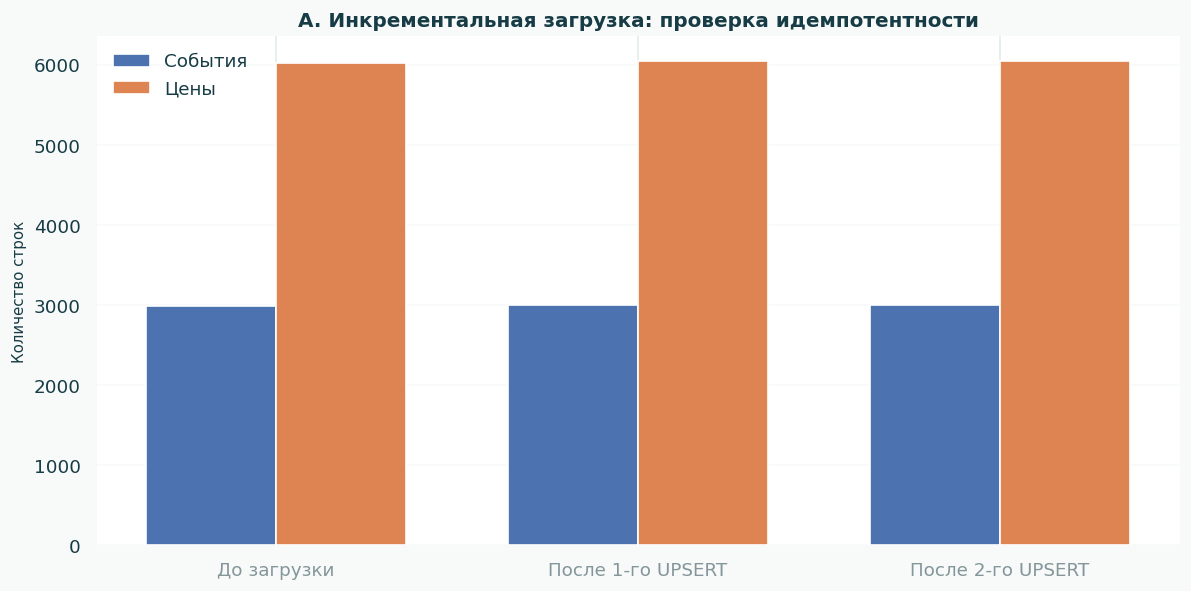

In [56]:
#@title A. Инкрементальная загрузка и доказательство идемпотентности
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).


#@title ★ A. Инкрементальная загрузка и проверка идемпотентности { display-mode: "form" }

# 1. Создаём отдельную копию рабочей базы данных
STAR_DB = WORK / f'lab2_star_variant_24_apteki.sqlite'

if STAR_DB.exists():
    STAR_DB.unlink()
star_conn = sqlite3.connect(STAR_DB)

# Копируем существующую базу, не изменяя оригинал
conn.backup(star_conn)
star_conn.execute("PRAGMA foreign_keys = ON")

# Проверяем наличие необходимых таблиц
tables = {
    row[0] for row in star_conn.execute(
        "SELECT name FROM sqlite_master WHERE type='table'"
    ).fetchall()
}

assert {"entities", "events", "prices"}.issubset(tables), (
    "В базе отсутствуют необходимые таблицы: entities, events, prices"
)

# 2. Генерируем данные за следующий день

rng_a = np.random.default_rng(701)

# Следующий день после последнего события
next_date = (
    pd.to_datetime(events_valid["event_date"]).max()
    + pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

n_new = 12

# Функция для получения следующего идентификатора
def next_ids(series, count):
    values = series.dropna().astype(str).tolist()
    numbers = [
        int(match.group(1))
        for value in values
        if (match := re.search(r"(\d+)$", value))
    ]

    assert numbers, "Не удалось определить числовую часть ID"

    # Сохраняем исходный префикс и длину номера
    last_id = values[
        max(range(len(values)),
            key=lambda i: int(re.search(r"(\d+)$", values[i]).group(1)))
    ]

    match = re.search(r"(\d+)$", last_id)
    prefix = last_id[:match.start()]
    width = len(match.group(1))

    start = max(numbers)

    return [
        f"{prefix}{start + i:0{width}d}"
        for i in range(1, count + 1)
    ]


new_eids = next_ids(events_valid["event_id"], n_new)

entity_pool = entities["entity_id"].tolist()

# Берём шаблон существующего события, чтобы сохранить дополнительные столбцы исходной структуры
event_template = events_valid.iloc[0].to_dict()

new_event_rows = []

for eid in new_eids:
    row = event_template.copy()

    row.update({
        "event_id": eid,
        "entity_id": rng_a.choice(entity_pool),
        "event_date": next_date,
        "volume_units": float(rng_a.integers(80, 350))
    })

    new_event_rows.append(row)

inc_events = pd.DataFrame(new_event_rows)

# 3. Создаём цены для новых событий

# Для каждого события создаём две записи цен
n_new_prices = n_new * 2

new_pids = next_ids(
    prices_valid["price_id"],
    n_new_prices
)

# Берём реальные цены из очищенного набора и немного изменяем их для учебной генерации
source_prices = prices_valid["unit_price"].to_numpy(dtype=float)

price_template = prices_valid.iloc[0].to_dict()

price_rows = []
price_num = 0

for eid in new_eids:

    for j in range(2):

        row = price_template.copy()

        original_price = rng_a.choice(source_prices)

        row.update({
            "price_id": new_pids[price_num],
            "event_id": eid,
            "unit_price": round(
                float(original_price * rng_a.uniform(0.95, 1.05)), 2
            )
        })

        price_rows.append(row)
        price_num += 1

inc_prices = pd.DataFrame(price_rows)

# 4. Функция UPSERT

def upsert_dataframe(connection, table, dataframe, primary_key):

    # Получаем реальные столбцы таблицы SQLite
    table_info = connection.execute(
        f'PRAGMA table_info("{table}")'
    ).fetchall()

    db_columns = [row[1] for row in table_info]

    # Оставляем только столбцы, существующие в БД
    columns = [
        col for col in db_columns
        if col in dataframe.columns
    ]

    assert primary_key in columns, (
        f"В таблице {table} отсутствует ключ {primary_key}"
    )

    # Формируем SQL-запрос
    column_sql = ", ".join(f'"{col}"' for col in columns)
    placeholders = ", ".join("?" for _ in columns)

    update_columns = [
        col for col in columns
        if col != primary_key
    ]

    if update_columns:
        update_sql = ", ".join(
            f'"{col}" = excluded."{col}"'
            for col in update_columns
        )

        conflict_sql = (
            f'ON CONFLICT("{primary_key}") DO UPDATE SET {update_sql}'
        )
    else:
        conflict_sql = (
            f'ON CONFLICT("{primary_key}") DO NOTHING'
        )

    sql = f"""
        INSERT INTO "{table}" ({column_sql})
        VALUES ({placeholders})
        {conflict_sql}
    """

    # Преобразуем даты и пропуски в совместимые с SQLite значения
    batch = dataframe[columns].copy()

    for col in batch.columns:
        if pd.api.types.is_datetime64_any_dtype(batch[col]):
            batch[col] = batch[col].dt.strftime("%Y-%m-%d")

    batch = batch.astype(object).where(pd.notna(batch), None)

    records = list(batch.itertuples(index=False, name=None))

    connection.executemany(sql, records)

# 5. Инкрементальная загрузка с автотестами

def upsert_next_day(connection, ev_batch, pr_batch):

    # Сначала проверяем данные, затем начинаем транзакцию
    validate_clean_batch(
        entities,
        ev_batch,
        pr_batch
    )

    with connection:

        upsert_dataframe(
            connection,
            "events",
            ev_batch,
            "event_id"
        )

        upsert_dataframe(
            connection,
            "prices",
            pr_batch,
            "price_id"
        )

    # Контроль ссылочной целостности после загрузки
    fk_errors = connection.execute(
        "PRAGMA foreign_key_check"
    ).fetchall()

    assert not fk_errors, (
        f"Нарушена ссылочная целостность SQLite: {fk_errors}"
    )


# 6. Фиксируем состояние БД

def incremental_state(connection, stage):

    counts = connection.execute("""
        SELECT
            (SELECT COUNT(*) FROM events),
            (SELECT COUNT(*) FROM prices)
    """).fetchone()

    # Контрольный расчёт: объём продаж * средняя цена по событию
    control_value = connection.execute("""
        WITH price_by_event AS (
            SELECT
                event_id,
                AVG(unit_price) AS avg_price
            FROM prices
            GROUP BY event_id
        )
        SELECT COALESCE(
            ROUND(SUM(ev.volume_units * pe.avg_price), 2),
            0
        )
        FROM events ev
        JOIN price_by_event pe
            ON ev.event_id = pe.event_id
    """).fetchone()[0]

    return {
        "Этап": stage,
        "Количество событий": counts[0],
        "Количество цен": counts[1],
        "Контрольный показатель, ₽": control_value
    }

# 7. Первый запуск и повторная загрузка

incremental_states = []

# Состояние до загрузки
incremental_states.append(
    incremental_state(star_conn, "До загрузки")
)

# Первый UPSERT
upsert_next_day(
    star_conn,
    inc_events,
    inc_prices
)

incremental_states.append(
    incremental_state(star_conn, "После 1-го UPSERT")
)

# Повторный UPSERT тех же данных
upsert_next_day(
    star_conn,
    inc_events,
    inc_prices
)

incremental_states.append(
    incremental_state(star_conn, "После 2-го UPSERT")
)

# 8. Проверяем идемпотентность

inc_check = pd.DataFrame(incremental_states)

# После повторного запуска количество записей не изменилось
assert (
    inc_check.loc[1, "Количество событий"]
    == inc_check.loc[2, "Количество событий"]
), "Повторная загрузка создала дубликаты событий"

assert (
    inc_check.loc[1, "Количество цен"]
    == inc_check.loc[2, "Количество цен"]
), "Повторная загрузка создала дубликаты цен"

# Контрольный показатель также не изменился
assert abs(
    inc_check.loc[1, "Контрольный показатель, ₽"]
    - inc_check.loc[2, "Контрольный показатель, ₽"]
) < 0.01, "После повторной загрузки изменился контрольный показатель"

# Проверяем, что новые записи действительно добавились
assert (
    inc_check.loc[1, "Количество событий"]
    - inc_check.loc[0, "Количество событий"]
    == n_new
), "Количество добавленных событий не совпадает с ожидаемым"

assert (
    inc_check.loc[1, "Количество цен"]
    - inc_check.loc[0, "Количество цен"]
    == len(inc_prices)
), "Количество добавленных цен не совпадает с ожидаемым"


# Дополнительная проверка уникальности ID непосредственно в SQLite
assert star_conn.execute("""
    SELECT COUNT(*) - COUNT(DISTINCT event_id)
    FROM events
""").fetchone()[0] == 0, "Обнаружены дубликаты event_id"

assert star_conn.execute("""
    SELECT COUNT(*) - COUNT(DISTINCT price_id)
    FROM prices
""").fetchone()[0] == 0, "Обнаружены дубликаты price_id"

# 9. Результаты

print(f"Дата новых событий: {next_date}")
print(f"Добавлено новых событий: {len(inc_events)}")
print(f"Добавлено новых записей цен: {len(inc_prices)}")

print("\nРЕЗУЛЬТАТЫ ИНКРЕМЕНТАЛЬНОЙ ЗАГРУЗКИ")

display(inc_check)

print("\nПРОВЕРКА ИДЕМПОТЕНТНОСТИ")

print("Количество событий после первого и второго UPSERT совпадает.")
print("Количество цен после первого и второго UPSERT совпадает.")
print("Контрольный показатель после повторной загрузки не изменился.")
print("Дубликаты первичных ключей отсутствуют.")

print("\n✅ Инкрементальная загрузка выполнена успешно.")
print("✅ Повторный запуск не создал дубликатов.")

DQ_INCREMENTAL_OK = True

# 10. Визуализация результатов

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(inc_check))

ax.bar(
    x - 0.18,
    inc_check["Количество событий"],
    width=0.36,
    label="События"
)

ax.bar(
    x + 0.18,
    inc_check["Количество цен"],
    width=0.36,
    label="Цены"
)

ax.set_xticks(x)
ax.set_xticklabels(inc_check["Этап"])

ax.set_ylabel("Количество строк")
ax.set_title(
    "A. Инкрементальная загрузка: проверка идемпотентности"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()
